# Bước B1 (phần so sánh) - chuỗi ablation B0 => B1a => B1b của Sequential Forecast LSTM có Q, 30 epoch, 3 hạt giống mỗi bước: B1a đổi Q quá khứ sang mm/ngày như nhãn (qmean => qmean_mmd), B1b thêm qmax quá khứ (qmax_mmd). Đo đóng góp của từng thay đổi so với nhiễu hạt giống (ngưỡng luật B*), theo từng lưu vực, theo epoch; xuất dự báo B1a, B1b theo hợp đồng NPZ của bộ đánh giá.
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.1, 6.1, 7 (dòng B0,
 B1a, B1b, B*), 9.5.
 Notebook Kaggle "05_B1_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = On, Persistence = Files only,
# Environment = Pin to original environment. Add Input:
   - Output 3 notebook 01_B0_LamaHCEExt_Train_Seed111 / _Seed222 / _Seed333 (Version 1 cả ba);
   - Output 3 notebook 03_B1a_LamaHCEExt_Train_Seed111 / _Seed222 / _Seed333 (Version 1 cả ba);
   - Output 3 notebook 04_B1b_LamaHCEExt_Train_Seed111 / _Seed222 / _Seed333 (Version 1 cả ba);
   - Output 02_A3_LamaHCEExt_Benchmarks (người 1, Version 1) - ngữ cảnh quan trắc, persistence, diện tích cho NPZ;
   - Dataset lamah-ce-ext - chỉ số test của tác giả.
 Không cần GPU, không cần thư viện NeuralHydrology: test_results.p chỉ cần xarray để đọc.
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Input, kiểm sha256 tệp của 9 run, giao thức, config đúng ablation, môi trường
   Phần 2 - Bảng 9 run cạnh tác giả, hiệu từng bước trên validation so với ngưỡng B*
   Phần 3 - So từng lưu vực: ba cặp bước, cặp cùng hạt giống, nhiễu hạt giống
   Phần 4 - Theo epoch: NSE validation và test của ba bước
   Phần 5 - Hình
   Phần 6 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
   Phần 7 - Lưu kết quả và môi trường

# Phần 1 - Tìm Input, kiểm sha256 tệp của 9 run, giao thức, config đúng ablation, môi trường
 Mỗi notebook hạt giống có <b0|b1a|b1b>_output/environment.json (hạt giống, thư mục run, commit thư viện, giao thức) và
 manifest.csv (7 tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó). Nhận Output theo
 environment.json (không theo tên đường dẫn), tính lại sha256 từng tệp. Kiểm config.yml của run (bản thư viện ghi) đúng
 chuỗi ablation: cùng hạt giống thì chỉ khác khóa đường dẫn, tên thí nghiệm và hai danh sách biến; B1a = B0 thay qmean
 bằng qmean_mmd tại cùng vị trí, B1b = B1a chèn qmax_mmd ngay sau qmean_mmd. Tìm thêm 2 tệp ngữ cảnh của A3 và chỉ số test
 của tác giả. Phần 1 chưa đạt thì dừng notebook.

In [1]:
# %% Phần 1 - Tìm Input, kiểm sha256 tệp của 9 run, giao thức, config đúng ablation, môi trường
# Mỗi notebook hạt giống có <b0|b1a|b1b>_output/environment.json (hạt giống, thư mục run, commit thư viện, giao thức) và
# manifest.csv (7 tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó). Nhận Output theo
# environment.json (không theo tên đường dẫn), tính lại sha256 từng tệp. Kiểm config.yml của run (bản thư viện ghi) đúng
# chuỗi ablation: cùng hạt giống thì chỉ khác khóa đường dẫn, tên thí nghiệm và hai danh sách biến; B1a = B0 thay qmean
# bằng qmean_mmd tại cùng vị trí, B1b = B1a chèn qmax_mmd ngay sau qmean_mmd. Tìm thêm 2 tệp ngữ cảnh của A3 và chỉ số test
# của tác giả. Phần 1 chưa đạt thì dừng notebook.
import hashlib
import json
import os
import platform
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("B1_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "b1_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b1_compare_work")
OUT_DIR = WORK_DIR / "b1_compare"
SEEDS = [111, 222, 333]
COMMIT = "f229e02bf98cbd979835a4b6cd503d0e3adb8bc3"   # fork research của bước B (data_on_gpu, sửa lưu best_model.pt)
RUNS = {"B0": {"output": "b0_output", "notebook": "01_B0_LamaHCEExt_Train_Seed{}"},
        "B1a": {"output": "b1a_output", "notebook": "03_B1a_LamaHCEExt_Train_Seed{}"},
        "B1b": {"output": "b1b_output", "notebook": "04_B1b_LamaHCEExt_Train_Seed{}"}}
VERSIONS = {step: {s: 1 for s in SEEDS} for step in RUNS}   # Version của bản lưu chính thức từng notebook hạt giống
N_FILES = 7                                                  # tệp chính mỗi run trong manifest.csv
PROTOCOL = {"epochs": 30, "early_stopping_patience": 30, "data_on_gpu": True, "deterministic": False}
PATH_KEYS = {"experiment_name", "run_dir", "train_dir", "img_log_dir", "data_dir"}   # được khác giữa các bước
INPUT_KEYS = ["hindcast_inputs", "dynamic_inputs"]
A3_VERSION = 1
A3_FILES = ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]
AUTHOR_METRICS_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                      "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv")
ENV_LIBS = ["numpy", "pandas", "xarray", "scipy", "matplotlib", "torch", "PyYAML"]
OUT_DIR.mkdir(parents=True, exist_ok=True)


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def show_checks(checks):
    # checks: [(mục, giá trị, cần, đạt)]; trả True nếu mọi dòng đạt.
    show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                               for a, b, c, d in checks]))
    return all(c[3] for c in checks)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def short(path, keep=3):
    # Đường dẫn tính từ INPUT_ROOT, dài thì giữ 2 cấp đầu và `keep` cấp cuối.
    parts = Path(path).relative_to(INPUT_ROOT).parts
    return "/".join(parts) if len(parts) <= keep + 2 else "/".join(parts[:2] + ("...",) + parts[-keep:])


def unique_file(root, name):
    # Đúng một tệp tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều (gắn trùng Input).
    hits = sorted(root.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 tệp '{name}' dưới {root}, thấy {len(hits)}: {hits}")
    return hits[0]


def run_dir(step, s):
    return ROOTS[step][s] / ENVS[step][s]["run_dir"]


def read_config(step, s):
    return yaml.safe_load((run_dir(step, s) / "config.yml").read_text(encoding="utf-8-sig"))


# (1) Output 3 notebook hạt giống của mỗi bước: nhận theo environment.json
ROOTS, ENVS = {}, {}                     # ROOTS[bước][hạt giống] = thư mục tương ứng /kaggle/working của notebook đó
for step, spec in RUNS.items():
    ROOTS[step] = {}
    for env_path in sorted(INPUT_ROOT.rglob(f"{spec['output']}/environment.json")):
        seed = json.loads(env_path.read_text(encoding="utf-8")).get("seed")
        if seed in ROOTS[step]:
            raise RuntimeError(f"{step} hạt giống {seed} có ở 2 Input: {ROOTS[step][seed]}, {env_path.parent.parent}")
        ROOTS[step][seed] = env_path.parent.parent
    if sorted(ROOTS[step]) != SEEDS:
        raise RuntimeError(f"Cần Output đúng 3 notebook {step} {SEEDS}, thấy {sorted(ROOTS[step])} - kiểm Add Input")
    ENVS[step] = {s: json.loads((r / spec["output"] / "environment.json").read_text(encoding="utf-8"))
                  for s, r in ROOTS[step].items()}
show("Output 9 notebook hạt giống", pd.DataFrame([{
    "bước": step, "hạt giống": s, "Version": VERSIONS[step][s], "thư mục Input": short(ROOTS[step][s]),
    "thư mục run": e["run_dir"].split("/")[-1], "commit thư viện": e["neuralhydrology_commit"][:7], "GPU": e["gpu"],
    "torch": e["libs"]["torch"], "epoch best_model.pt": e["summary"]["saved_epoch"], "số epoch": e["summary"]["n_epochs"]}
    for step in RUNS for s, e in sorted(ENVS[step].items())]))

# (2) Kiểm sha256 từng tệp trong manifest.csv
rows = []
for step, spec in RUNS.items():
    for s, root in sorted(ROOTS[step].items()):
        man = pd.read_csv(root / spec["output"] / "manifest.csv")
        for rel, digest in zip(man["tệp"], man["sha256"]):
            f = root / rel
            got = sha256(f) if f.exists() else "THIẾU"
            rows.append({"bước": step, "hạt giống": s, "tệp": rel.split("/", 2)[-1],
                         "sha256 khớp": "ĐẠT" if got == digest else "KHÔNG"})
SHA_DF = pd.DataFrame(rows)
SHA_DF["tệp"] = SHA_DF["tệp"].str.replace(r"^events\.out\.tfevents\..*", "events.out.tfevents.*", regex=True)
show("sha256 tệp chính của 9 run (so với manifest.csv của từng notebook)",
     SHA_DF.assign(run=SHA_DF["bước"] + " " + SHA_DF["hạt giống"].astype(str))
     .pivot(index="tệp", columns="run", values="sha256 khớp").reset_index())

# (3) Config đúng chuỗi ablation, so cùng hạt giống
CONFIGS = {step: {s: read_config(step, s) for s in SEEDS} for step in RUNS}


def expected_inputs(step, base):
    # Danh sách biến bước `step` phải có, dựng từ danh sách của B0 cùng hạt giống.
    out = ["qmean_mmd" if v == "qmean" else v for v in base] if step != "B0" else list(base)
    if step == "B1b":
        out.insert(out.index("qmean_mmd") + 1, "qmax_mmd")
    return out


rows, ablation_ok = [], True
for step in ["B1a", "B1b"]:
    prev = {"B1a": "B0", "B1b": "B1a"}[step]
    for s in SEEDS:
        a, b = CONFIGS[prev][s], CONFIGS[step][s]
        diff = sorted(k for k in set(a) | set(b) if a.get(k) != b.get(k))
        inputs_ok = all(b[k] == expected_inputs(step, CONFIGS["B0"][s][k]) for k in INPUT_KEYS)
        keys_ok = set(diff) <= PATH_KEYS | set(INPUT_KEYS)
        ablation_ok &= inputs_ok and keys_ok
        rows.append({"cặp": f"{step} so với {prev}", "hạt giống": s,
                     "khóa khác (ngoài đường dẫn)": ", ".join(k for k in diff if k not in PATH_KEYS) or "-",
                     "biến quá khứ": f"{len(a['hindcast_inputs'])} => {len(b['hindcast_inputs'])}",
                     "biến dynamic": f"{len(a['dynamic_inputs'])} => {len(b['dynamic_inputs'])}",
                     "biến Q quá khứ": ", ".join(v for v in b["hindcast_inputs"] if v.startswith("q")),
                     "danh sách biến đúng": "ĐẠT" if inputs_ok else "KHÔNG",
                     "chỉ khác khóa cho phép": "ĐẠT" if keys_ok else "KHÔNG"})
show("Config của run (bản thư viện ghi): mỗi bước chỉ thêm một thay đổi so với bước trước, cùng hạt giống", pd.DataFrame(rows))

# (4) Ngữ cảnh A3 và chỉ số test của tác giả
A3_PATHS = {name: unique_file(INPUT_ROOT, name) for name in A3_FILES}
author_hits = [p for p in INPUT_ROOT.rglob("test_metrics.csv") if p.as_posix().endswith(AUTHOR_METRICS_REL)]
if len(author_hits) != 1:
    raise FileNotFoundError(f"Cần đúng 1 tệp chỉ số test của tác giả ({AUTHOR_METRICS_REL}), thấy {len(author_hits)} - gắn lamah-ce-ext")
AUTHOR_METRICS_PATH = author_hits[0]
show("Tệp ngữ cảnh", pd.DataFrame(
    [{"tệp": n, "đường dẫn": short(p), "KB": round(p.stat().st_size / 1e3, 1)} for n, p in A3_PATHS.items()]
    + [{"tệp": "test_metrics.csv của tác giả", "đường dẫn": short(AUTHOR_METRICS_PATH),
        "KB": round(AUTHOR_METRICS_PATH.stat().st_size / 1e3, 1)}]), digits=1)

# (5) Môi trường của notebook này
ENV = {"Python": platform.python_version(), **{lib: metadata.version(lib) for lib in ENV_LIBS},
       "Số CPU": os.cpu_count(), "Ngày dựng ảnh Kaggle":
       Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"}
show("Môi trường", pd.DataFrame({"mục": list(ENV), "giá trị": [str(v) for v in ENV.values()]}))

n_files = SHA_DF.groupby(["bước", "hạt giống"]).size()
all_envs = [e for step in RUNS for e in ENVS[step].values()]
torch_all = sorted({e["libs"]["torch"] for e in all_envs})
proto_bad = [f"{step} {s}" for step in RUNS for s, e in ENVS[step].items()
             if any(e["protocol"].get(k) != v for k, v in PROTOCOL.items())]
checks = [(f"Mỗi run đủ {N_FILES} tệp chính", n_files.to_dict(), f"{N_FILES} mỗi run", n_files.eq(N_FILES).all()),
          ("sha256 khớp manifest", f"{int((SHA_DF['sha256 khớp'] == 'ĐẠT').sum())} / {len(SHA_DF)}", "tất cả",
           (SHA_DF["sha256 khớp"] == "ĐẠT").all()),
          (f"Cùng commit thư viện {COMMIT[:7]}", sorted({e["neuralhydrology_commit"][:7] for e in all_envs}), COMMIT[:7],
           all(e["neuralhydrology_commit"] == COMMIT for e in all_envs)),
          ("Cùng phiên bản torch", torch_all, "1 bản", len(torch_all) == 1),
          ("Cùng giao thức (30 epoch, patience 30, data_on_gpu, không tất định)", proto_bad or "cả 9 run", "cả 9 run",
           not proto_bad),
          ("Config đúng chuỗi ablation", "xem bảng config", "ĐẠT ở 6 dòng", ablation_ok)]
if not show_checks(checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - kiểm Input rồi chạy lại")
print("=> Đạt. Chạy Phần 2.")


bước,hạt giống,Version,thư mục Input,thư mục run,commit thư viện,GPU,torch,epoch best_model.pt,số epoch
B0,111,1,notebooks/hunhngcthng/01-b0-lamahceext-train-seed111,B0_SeqLSTM_Q_seed111_2510_175050,f229e02,Tesla T4,2.11.0+cu128,25,30
B0,222,1,notebooks/hunhngcthng/01-b0-lamahceext-train-seed222,B0_SeqLSTM_Q_seed222_2510_175613,f229e02,Tesla T4,2.11.0+cu128,15,30
B0,333,1,notebooks/hunhngcthng/01-b0-lamahceext-train-seed333,B0_SeqLSTM_Q_seed333_2510_232832,f229e02,Tesla T4,2.11.0+cu128,14,30
B1a,111,1,notebooks/hunhngcthng/03-b1a-lamahceext-train-seed111,B1a_SeqLSTM_Q_seed111_2610_080735,f229e02,Tesla T4,2.11.0+cu128,20,30
B1a,222,1,notebooks/hunhngcthng/03-b1a-lamahceext-train-seed222,B1a_SeqLSTM_Q_seed222_2710_150153,f229e02,Tesla T4,2.11.0+cu128,4,30
B1a,333,1,notebooks/hunhngcthng/03-b1a-lamahceext-train-seed333,B1a_SeqLSTM_Q_seed333_2710_152304,f229e02,Tesla T4,2.11.0+cu128,10,30
B1b,111,1,notebooks/hunhngcthng/04-b1b-lamahceext-train-seed111,B1b_SeqLSTM_Q_seed111_2710_154405,f229e02,Tesla T4,2.11.0+cu128,11,30
B1b,222,1,notebooks/hunhngcthng/04-b1b-lamahceext-train-seed222,B1b_SeqLSTM_Q_seed222_2710_153831,f229e02,Tesla T4,2.11.0+cu128,8,30
B1b,333,1,notebooks/hunhngcthng/04-b1b-lamahceext-train-seed333,B1b_SeqLSTM_Q_seed333_2710_182317,f229e02,Tesla T4,2.11.0+cu128,19,30


tệp,B0 111,B0 222,B0 333,B1a 111,B1a 222,B1a 333,B1b 111,B1b 222,B1b 333
best_model.pt,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
config.yml,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
events.out.tfevents.*,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
output.log,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_metrics.csv,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_results.p,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT
train_data/train_data_scaler.yml,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT,ĐẠT


cặp,hạt giống,khóa khác (ngoài đường dẫn),biến quá khứ,biến dynamic,biến Q quá khứ,danh sách biến đúng,chỉ khác khóa cho phép
B1a so với B0,111,"dynamic_inputs, hindcast_inputs",32 => 32,37 => 37,qmean_mmd,ĐẠT,ĐẠT
B1a so với B0,222,"dynamic_inputs, hindcast_inputs",32 => 32,37 => 37,qmean_mmd,ĐẠT,ĐẠT
B1a so với B0,333,"dynamic_inputs, hindcast_inputs",32 => 32,37 => 37,qmean_mmd,ĐẠT,ĐẠT
B1b so với B1a,111,"dynamic_inputs, hindcast_inputs",32 => 33,37 => 38,"qmean_mmd, qmax_mmd",ĐẠT,ĐẠT
B1b so với B1a,222,"dynamic_inputs, hindcast_inputs",32 => 33,37 => 38,"qmean_mmd, qmax_mmd",ĐẠT,ĐẠT
B1b so với B1a,333,"dynamic_inputs, hindcast_inputs",32 => 33,37 => 38,"qmean_mmd, qmax_mmd",ĐẠT,ĐẠT


tệp,đường dẫn,KB
A3_persistence_predictions.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_persistence_predictions.npz,8136.7
A3_Q_source_window.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_Q_source_window.npz,3349.0
test_metrics.csv của tác giả,datasets/hunhngcthng/.../test/best_model/test_metrics.csv,18.8


mục,giá trị
Python,3.13.15
numpy,2.1.3
pandas,2.3.3
xarray,2025.12.0
scipy,1.16.3
matplotlib,3.10.0
torch,2.11.0+cpu
PyYAML,6.0.3
Số CPU,4
Ngày dựng ảnh Kaggle,20261022-041801


mục,giá trị,cần,đạt
Mỗi run đủ 7 tệp chính,"{('B0', 111): 7, ('B0', 222): 7, ('B0', 333): 7, ('B1a', 111): 7, ('B1a', 222): 7, ('B1a', 333): 7, ('B1b', 111): 7, ('B1b', 222): 7, ('B1b', 333): 7}",7 mỗi run,ĐẠT
sha256 khớp manifest,63 / 63,tất cả,ĐẠT
Cùng commit thư viện f229e02,['f229e02'],f229e02,ĐẠT
Cùng phiên bản torch,['2.11.0+cu128'],1 bản,ĐẠT
"Cùng giao thức (30 epoch, patience 30, data_on_gpu, không tất định)",cả 9 run,cả 9 run,ĐẠT
Config đúng chuỗi ablation,xem bảng config,ĐẠT ở 6 dòng,ĐẠT


=> Đạt. Chạy Phần 2.


# Phần 2 - Bảng 9 run cạnh tác giả, hiệu từng bước trên validation so với ngưỡng B*
 Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv, đã kiểm sha256 ở Phần 1), tính
 lại trung vị và đối chiếu tóm tắt notebook hạt giống đã ghi (<bước>_output/summary_<run>.json, curve_<run>.csv). Trung
 vị bỏ NaN như logger.py dòng 210 của thư viện. Tầng chọn (02_Pipeline.md Mục 6.1) chỉ dùng NSE trung vị validation tại
 best_model.pt: hiệu giữa hai bước = hiệu trung bình 3 hạt giống, so với ngưỡng B* = độ lệch chuẩn (ddof=1) của NSE trung
 vị validation giữa 3 hạt giống B0 (Mục 7, dòng B*; 02_B0_LamaHCEExt_Compare Phần 2 ra 0.0079). Hiệu trên test chỉ đặt
 cạnh để báo cáo. Cột "NSE test cao nhất trong 30 epoch" chỉ để thấy chọn theo validation mất bao nhiêu so với chọn theo
 test (không dùng để chọn). Dừng notebook chỉ khi số tính lại không khớp tóm tắt (Input sai).

In [2]:
# %% Phần 2 - Bảng 9 run cạnh tác giả, hiệu từng bước trên validation so với ngưỡng B*
# Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv, đã kiểm sha256 ở Phần 1), tính
# lại trung vị và đối chiếu tóm tắt notebook hạt giống đã ghi (<bước>_output/summary_<run>.json, curve_<run>.csv). Trung
# vị bỏ NaN như logger.py dòng 210 của thư viện. Tầng chọn (02_Pipeline.md Mục 6.1) chỉ dùng NSE trung vị validation tại
# best_model.pt: hiệu giữa hai bước = hiệu trung bình 3 hạt giống, so với ngưỡng B* = độ lệch chuẩn (ddof=1) của NSE trung
# vị validation giữa 3 hạt giống B0 (Mục 7, dòng B*; 02_B0_LamaHCEExt_Compare Phần 2 ra 0.0079). Hiệu trên test chỉ đặt
# cạnh để báo cáo. Cột "NSE test cao nhất trong 30 epoch" chỉ để thấy chọn theo validation mất bao nhiêu so với chọn theo
# test (không dùng để chọn). Dừng notebook chỉ khi số tính lại không khớp tóm tắt (Input sai).
SUM_TOL = 1e-9
STAT_COLS = ["NSE trung vị validation", "NSE trung vị test", "KGE trung vị test", "giờ huấn luyện"]
STEP_PAIRS = [("B1a", "B0", "đơn vị Q (m³/s => mm/ngày)"), ("B1b", "B1a", "thêm qmax quá khứ"), ("B1b", "B0", "cả hai")]


def read_metrics(path):
    # test_metrics.csv của NeuralHydrology: cột đầu là mã lưu vực => chuẩn hóa thành str(int) như bộ đánh giá.
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    return m


def out_file(step, s, name):
    return ROOTS[step][s] / RUNS[step]["output"] / name


EXP = {step: {s: ENVS[step][s]["experiment_name"] for s in SEEDS} for step in RUNS}
SUMMARY = {step: {s: json.loads(out_file(step, s, f"summary_{EXP[step][s]}.json").read_text(encoding="utf-8"))
                  for s in SEEDS} for step in RUNS}
CURVES = {step: {s: pd.read_csv(out_file(step, s, f"curve_{EXP[step][s]}.csv")).set_index("epoch") for s in SEEDS}
          for step in RUNS}
TEST_METRICS = {step: {s: read_metrics(run_dir(step, s) / "test" / "best_model" / "test_metrics.csv") for s in SEEDS}
                for step in RUNS}
AUTHOR_METRICS = read_metrics(AUTHOR_METRICS_PATH)
AUTHOR_NSE = float(AUTHOR_METRICS["NSE"].median())
BEST = {step: {s: SUMMARY[step][s]["saved_epoch"] for s in SEEDS} for step in RUNS}

rows = []
for step in RUNS:
    for s in SEEDS:
        m, c, e = TEST_METRICS[step][s], CURVES[step][s], BEST[step][s]
        rows.append({"bước": step, "hạt giống": s, "epoch best_model.pt": e, "số epoch": SUMMARY[step][s]["n_epochs"],
                     "NSE trung vị validation": float(c.loc[e, "NSE trung vị validation (tệp)"]),
                     "NSE trung vị test": float(m["NSE"].median()), "KGE trung vị test": float(m["KGE"].median()),
                     "lưu vực có NSE": int(m["NSE"].notna().sum()), "giờ huấn luyện": SUMMARY[step][s]["train_hours"],
                     "NSE test cao nhất trong 30 epoch (epoch)": f"{c['NSE trung vị test'].max():.4f} "
                                                                 f"({int(c['NSE trung vị test'].idxmax())})"})
rows.append({"bước": "tác giả", "NSE trung vị test": AUTHOR_NSE, "KGE trung vị test": float(AUTHOR_METRICS["KGE"].median()),
             "lưu vực có NSE": int(AUTHOR_METRICS["NSE"].notna().sum())})
SEED_TABLE = pd.DataFrame(rows).astype({c: "Int64" for c in ["hạt giống", "epoch best_model.pt", "số epoch"]})
SEED_TABLE["Δ NSE test so với tác giả"] = SEED_TABLE["NSE trung vị test"] - AUTHOR_NSE
show("Test 2014-2017 và validation 2010-2013 tại best_model.pt: B0, B1a, B1b (30 epoch), tác giả", SEED_TABLE)

# Thống kê qua 3 hạt giống của từng bước; ngưỡng B*
STATS = pd.DataFrame([{"bước": step, "chỉ số": c, "trung bình": sub[c].mean(), "độ lệch chuẩn (ddof=1)": sub[c].std(ddof=1),
                       "min": sub[c].min(), "max": sub[c].max()}
                      for step in RUNS for sub in [SEED_TABLE[SEED_TABLE["bước"] == step]] for c in STAT_COLS])
show("Qua 3 hạt giống", STATS)
st_idx = STATS.set_index(["bước", "chỉ số"])
BSTAR_SD = float(st_idx.loc[("B0", "NSE trung vị validation"), "độ lệch chuẩn (ddof=1)"])


def step_values(step, col):
    return SEED_TABLE[SEED_TABLE["bước"] == step].set_index("hạt giống")[col]


# Hiệu từng bước: trung bình 3 hạt giống (kết luận), từng hạt giống (đặt cạnh)
rows = []
for new, old, what in STEP_PAIRS:
    dv = step_values(new, "NSE trung vị validation") - step_values(old, "NSE trung vị validation")
    dt = step_values(new, "NSE trung vị test") - step_values(old, "NSE trung vị test")
    d = float(dv.mean())
    verdict = "tốt hơn, vượt ngưỡng" if d > BSTAR_SD else ("kém hơn, vượt ngưỡng" if d < -BSTAR_SD else "trong ngưỡng nhiễu")
    rows.append({"cặp": f"{new} - {old}", "thay đổi": what, "Δ NSE validation (TB 3 hạt giống)": d,
                 "Δ / ngưỡng B*": d / BSTAR_SD, "kết luận tầng chọn": verdict,
                 "Δ validation từng hạt giống": ", ".join(f"{v:+.4f}" for v in dv),
                 "Δ NSE test (TB 3 hạt giống)": float(dt.mean()),
                 "Δ test từng hạt giống": ", ".join(f"{v:+.4f}" for v in dt)})
STEP_DELTA = pd.DataFrame(rows)
show(f"Hiệu từng bước trên NSE trung vị (ngưỡng B* = độ lệch chuẩn validation 3 hạt giống B0 = {BSTAR_SD:.4f})", STEP_DELTA)

# Thời gian (bảng theo epoch của từng hạt giống, Phần 5 notebook hạt giống)
TIMING = pd.DataFrame([{
    "bước": step, "hạt giống": s, "phút huấn luyện/epoch (trung vị)": CURVES[step][s]["phút huấn luyện"].median(),
    "phút validation/lượt (trung vị từ epoch 2)": CURVES[step][s]["phút validation"].iloc[1:].median(),
    "giờ huấn luyện (tiến trình)": SUMMARY[step][s]["train_hours"],
    "phút chấm test/epoch (trung vị)": SUMMARY[step][s]["test_eval_minutes_median"]} for step in RUNS for s in SEEDS])
show("Thời gian trên Kaggle T4 (data_on_gpu, không bật chế độ tất định)", TIMING, digits=2)


def max_gap(get_a, get_b):
    return max(abs(get_a(step, s) - get_b(step, s)) for step in RUNS for s in SEEDS)


nse_gap = max_gap(lambda st, s: float(TEST_METRICS[st][s]["NSE"].median()),
                  lambda st, s: SUMMARY[st][s]["test_nse_median_best_model"])
val_gap = max_gap(lambda st, s: float(CURVES[st][s].loc[BEST[st][s], "NSE trung vị validation (tệp)"]),
                  lambda st, s: SUMMARY[st][s]["val_nse_median_best_model"])
best_bad = [f"{st} {s}" for st in RUNS for s in SEEDS
            if not (SUMMARY[st][s]["n_epochs"] == 30 and BEST[st][s] == SUMMARY[st][s]["true_best_epoch"]
                    == int(CURVES[st][s]["NSE trung vị validation (tệp)"].idxmax()))]
checks = [("Mỗi run đủ lưu vực như tác giả", sorted({len(TEST_METRICS[st][s]) for st in RUNS for s in SEEDS}),
           len(AUTHOR_METRICS), all(set(TEST_METRICS[st][s].index) == set(AUTHOR_METRICS.index) for st in RUNS for s in SEEDS)),
          ("NSE test tính lại khớp tóm tắt", nse_gap, f"<= {SUM_TOL}", nse_gap <= SUM_TOL),
          ("NSE validation tại best_model.pt khớp tóm tắt", val_gap, f"<= {SUM_TOL}", val_gap <= SUM_TOL),
          ("Đủ 30 epoch, best_model.pt = epoch NSE validation cao nhất", best_bad or "cả 9 run", "cả 9 run", not best_bad)]
if not show_checks(checks):
    raise RuntimeError("Phần 2 CHƯA đạt: số tính lại không khớp tóm tắt (dòng KHÔNG ở trên) - kiểm Input")
print(f"=> Ngưỡng B* {BSTAR_SD:.4f}. " + "; ".join(f"{r['cặp']}: Δ validation {r['Δ NSE validation (TB 3 hạt giống)']:+.4f} "
                                                 f"({r['kết luận tầng chọn']})" for _, r in STEP_DELTA.iterrows())
      + ". Chạy Phần 3.")


bước,hạt giống,epoch best_model.pt,số epoch,NSE trung vị validation,NSE trung vị test,KGE trung vị test,lưu vực có NSE,giờ huấn luyện,NSE test cao nhất trong 30 epoch (epoch),Δ NSE test so với tác giả
B0,111,25,30,0.7423,0.7072,0.7631,450,1.8319,0.7107 (14),0.0019
B0,222,15,30,0.7541,0.7038,0.7910,450,1.9323,0.7083 (28),-0.0015
B0,333,14,30,0.7574,0.7059,0.7860,450,1.7637,0.7077 (27),0.0006
B1a,111,20,30,0.7561,0.7107,0.7863,450,1.7935,0.7201 (14),0.0054
B1a,222,4,30,0.7548,0.6997,0.7753,450,1.8401,0.7165 (13),-0.0056
B1a,333,10,30,0.7564,0.7125,0.7838,450,1.8380,0.7125 (10),0.0072
B1b,111,11,30,0.7791,0.7133,0.7758,450,1.8806,0.7274 (10),0.0081
B1b,222,8,30,0.7712,0.7133,0.7817,450,1.8230,0.7283 (4),0.0080
B1b,333,19,30,0.7732,0.7282,0.8051,450,1.8563,0.7282 (19),0.0229
tác giả,-,-,-,-,0.7053,0.7671,450,-,-,0.0000


bước,chỉ số,trung bình,độ lệch chuẩn (ddof=1),min,max
B0,NSE trung vị validation,0.7513,0.0079,0.7423,0.7574
B0,NSE trung vị test,0.7056,0.0017,0.7038,0.7072
B0,KGE trung vị test,0.7800,0.0148,0.7631,0.7910
B0,giờ huấn luyện,1.8426,0.0848,1.7637,1.9323
B1a,NSE trung vị validation,0.7558,0.0008,0.7548,0.7564
B1a,NSE trung vị test,0.7076,0.0069,0.6997,0.7125
B1a,KGE trung vị test,0.7818,0.0058,0.7753,0.7863
B1a,giờ huấn luyện,1.8239,0.0263,1.7935,1.8401
B1b,NSE trung vị validation,0.7745,0.0041,0.7712,0.7791
B1b,NSE trung vị test,0.7183,0.0086,0.7133,0.7282


cặp,thay đổi,Δ NSE validation (TB 3 hạt giống),Δ / ngưỡng B*,kết luận tầng chọn,Δ validation từng hạt giống,Δ NSE test (TB 3 hạt giống),Δ test từng hạt giống
B1a - B0,đơn vị Q (m³/s => mm/ngày),0.0045,0.5641,trong ngưỡng nhiễu,"+0.0137, +0.0007, -0.0010",0.0020,"+0.0034, -0.0041, +0.0066"
B1b - B1a,thêm qmax quá khứ,0.0188,2.3674,"tốt hơn, vượt ngưỡng","+0.0231, +0.0164, +0.0168",0.0106,"+0.0027, +0.0136, +0.0157"
B1b - B0,cả hai,0.0233,2.9314,"tốt hơn, vượt ngưỡng","+0.0368, +0.0171, +0.0158",0.0126,"+0.0061, +0.0095, +0.0223"


bước,hạt giống,phút huấn luyện/epoch (trung vị),phút validation/lượt (trung vị từ epoch 2),giờ huấn luyện (tiến trình),phút chấm test/epoch (trung vị)
B0,111,2.70,0.84,1.83,0.84
B0,222,2.89,0.85,1.93,0.85
B0,333,2.60,0.81,1.76,0.80
B1a,111,2.64,0.82,1.79,0.82
B1a,222,2.72,0.83,1.84,0.83
B1a,333,2.74,0.83,1.84,0.83
B1b,111,2.78,0.85,1.88,0.86
B1b,222,2.67,0.84,1.82,0.84
B1b,333,2.75,0.84,1.86,0.84


mục,giá trị,cần,đạt
Mỗi run đủ lưu vực như tác giả,[451],451,ĐẠT
NSE test tính lại khớp tóm tắt,0.0,<= 1e-09,ĐẠT
NSE validation tại best_model.pt khớp tóm tắt,0.0,<= 1e-09,ĐẠT
"Đủ 30 epoch, best_model.pt = epoch NSE validation cao nhất",cả 9 run,cả 9 run,ĐẠT


=> Ngưỡng B* 0.0079. B1a - B0: Δ validation +0.0045 (trong ngưỡng nhiễu); B1b - B1a: Δ validation +0.0188 (tốt hơn, vượt ngưỡng); B1b - B0: Δ validation +0.0233 (tốt hơn, vượt ngưỡng). Chạy Phần 3.


# Phần 3 - So từng lưu vực: ba cặp bước, cặp cùng hạt giống, nhiễu hạt giống
 Kiểm định ghép cặp theo lưu vực, cùng cách của bộ đánh giá (01_Evaluation_LamaHCEExt.py Phần 7.1, như B0 Compare Phần 4:
 Wilcoxon hai phía zero_method="wilcox", correction=False, method="auto"; Cohen's dz = trung bình hiệu / độ lệch chuẩn
 hiệu; Holm trong từng họ). Ba họ trên NSE test của best_model.pt:
   (1) ba cặp bước, mỗi lưu vực lấy NSE trung bình 3 hạt giống - kết luận chính (B1b khác B1a về số tham số nên cùng hạt
       giống không cùng khởi tạo, thứ tự lô; trung bình 3 hạt giống dùng chung cho cả ba cặp);
   (2) cặp cùng hạt giống B1a - B0 (cùng khởi tạo, cùng thứ tự lô => hiệu chỉ do đổi đơn vị Q) và B1b - B1a (đặt cạnh);
   (3) mốc nhiễu: 3 cặp hạt giống trong mỗi bước.
 Đặt cạnh: họ (1) trên NSE validation từng lưu vực (validation/model_epoch<best>/validation_metrics.csv); hiệu theo mức NSE
 (5 mức như B0 Compare, xếp theo NSE trung bình B0) và theo diện tích area_gov (5 nhóm bằng số lưu vực, tương quan
 Spearman giữa hiệu và log diện tích) - kiểm giả thuyết đơn vị m³/s làm lưu vực nhỏ, lớn lệch thang chuẩn hóa. Lưu vực so là
 lưu vực có NSE ở mọi run. Kết quả là phát hiện, không dừng notebook.

In [3]:
# %% Phần 3 - So từng lưu vực: ba cặp bước, cặp cùng hạt giống, nhiễu hạt giống
# Kiểm định ghép cặp theo lưu vực, cùng cách của bộ đánh giá (01_Evaluation_LamaHCEExt.py Phần 7.1, như B0 Compare Phần 4:
# Wilcoxon hai phía zero_method="wilcox", correction=False, method="auto"; Cohen's dz = trung bình hiệu / độ lệch chuẩn
# hiệu; Holm trong từng họ). Ba họ trên NSE test của best_model.pt:
#   (1) ba cặp bước, mỗi lưu vực lấy NSE trung bình 3 hạt giống - kết luận chính (B1b khác B1a về số tham số nên cùng hạt
#       giống không cùng khởi tạo, thứ tự lô; trung bình 3 hạt giống dùng chung cho cả ba cặp);
#   (2) cặp cùng hạt giống B1a - B0 (cùng khởi tạo, cùng thứ tự lô => hiệu chỉ do đổi đơn vị Q) và B1b - B1a (đặt cạnh);
#   (3) mốc nhiễu: 3 cặp hạt giống trong mỗi bước.
# Đặt cạnh: họ (1) trên NSE validation từng lưu vực (validation/model_epoch<best>/validation_metrics.csv); hiệu theo mức NSE
# (5 mức như B0 Compare, xếp theo NSE trung bình B0) và theo diện tích area_gov (5 nhóm bằng số lưu vực, tương quan
# Spearman giữa hiệu và log diện tích) - kiểm giả thuyết đơn vị m³/s làm lưu vực nhỏ, lớn lệch thang chuẩn hóa. Lưu vực so là
# lưu vực có NSE ở mọi run. Kết quả là phát hiện, không dừng notebook.
from scipy import stats

NSE_LEVELS = [-np.inf, 0.0, 0.5, 0.7, 0.85, np.inf]
NSE_LEVEL_NAMES = ["< 0", "0 - 0.5", "0.5 - 0.7", "0.7 - 0.85", ">= 0.85"]
N_AREA_GROUPS = 5


def paired_test(left, right):
    # Chép từ B0 Compare Phần 4 (bộ đánh giá Phần 7.1), dương = `left` tốt hơn.
    left, right = np.asarray(left, dtype=float), np.asarray(right, dtype=float)
    ok = np.isfinite(left) & np.isfinite(right)
    d = left[ok] - right[ok]
    sd_ = float(np.std(d, ddof=1)) if len(d) > 1 else np.nan
    p = 1.0 if np.all(d == 0) else float(stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided",
                                                        correction=False, method="auto").pvalue)
    return {"số cặp": len(d), "trái tốt hơn": int((d > 0).sum()), "trái kém hơn": int((d < 0).sum()),
            "trung bình hiệu": float(d.mean()), "trung vị hiệu": float(np.median(d)),
            "Cohen's dz": float(d.mean() / sd_) if sd_ > 0 else np.nan, "p Wilcoxon": p}


def holm(p):
    # Holm-Bonferroni: p đã sắp tăng nhân (m - i), lấy max tích lũy, chặn ở 1.
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(p)
    out[order] = adj
    return out


def basin_table(metrics):
    # metrics[bước][hạt giống] = bảng chỉ số theo lưu vực => cột "<bước> <hạt giống>", "<bước> TB", "<bước> SD".
    t = pd.DataFrame({f"{st} {s}": metrics[st][s]["NSE"] for st in RUNS for s in SEEDS})
    for st in RUNS:
        c = [f"{st} {s}" for s in SEEDS]
        t[f"{st} TB"] = t[c].mean(axis=1)
        t[f"{st} SD"] = t[c].std(axis=1, ddof=1)
    return t


def run_family(table, family, pairs):
    res = [{"họ": family, "trái": l, "phải": r, **paired_test(table[l], table[r])} for l, r in pairs]
    for r_, p_adj in zip(res, holm([r_["p Wilcoxon"] for r_ in res])):
        r_["p Holm"] = p_adj
    return res


VAL_METRICS = {st: {s: read_metrics(run_dir(st, s) / "validation" / f"model_epoch{BEST[st][s]:03d}" / "validation_metrics.csv")
                    for s in SEEDS} for st in RUNS}
BASIN_NSE = basin_table(TEST_METRICS).dropna()
BASIN_NSE["tác giả"] = AUTHOR_METRICS["NSE"].reindex(BASIN_NSE.index)
BASIN_NSE.index.name = "basin"
BASIN_VAL = basin_table(VAL_METRICS).dropna()
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    AREA = pd.Series(np.array(d["area_gov_km2"], dtype=float), index=[str(int(str(b).strip())) for b in d["basin_ids"]])
BASIN_NSE["diện tích (km²)"] = AREA.reindex(BASIN_NSE.index)
STEP_COLS = [(f"{new} TB", f"{old} TB") for new, old, _ in STEP_PAIRS]
for (l, r), (new, old, _) in zip(STEP_COLS, STEP_PAIRS):
    BASIN_NSE[f"Δ {new}-{old}"] = BASIN_NSE[l] - BASIN_NSE[r]
BASIN_NSE["mức NSE"] = pd.cut(BASIN_NSE["B0 TB"], NSE_LEVELS, labels=NSE_LEVEL_NAMES, right=False)
BASIN_NSE["nhóm diện tích"] = pd.qcut(BASIN_NSE["diện tích (km²)"], N_AREA_GROUPS)

# (1)-(3) Kiểm định ghép cặp trên test; họ (1) thêm trên validation
fam = {"(1) ba cặp bước, TB 3 hạt giống": STEP_COLS,
       "(2) cùng hạt giống": [(f"B1a {s}", f"B0 {s}") for s in SEEDS] + [(f"B1b {s}", f"B1a {s}") for s in SEEDS],
       "(3) nhiễu: cặp hạt giống trong bước": [(f"{st} {a}", f"{st} {b}") for st in RUNS
                                               for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]]}
rows = [dict(r, kỳ="test") for name, pairs in fam.items() for r in run_family(BASIN_NSE, name, pairs)]
rows += [dict(r, kỳ="validation") for r in run_family(BASIN_VAL, "(1) ba cặp bước, TB 3 hạt giống", STEP_COLS)]
PAIRED = pd.DataFrame(rows)[["kỳ", "họ", "trái", "phải", "số cặp", "trái tốt hơn", "trái kém hơn", "trung bình hiệu",
                             "trung vị hiệu", "Cohen's dz", "p Wilcoxon", "p Holm"]]
PAIRED.to_csv(OUT_DIR / "B1_paired_tests.csv", index=False)
show("Wilcoxon ghép cặp theo lưu vực (NSE; dương = bên trái tốt hơn; Holm trong từng họ)", PAIRED)

# Mốc nhiễu đặt cạnh hiệu giữa bước: trung vị |hiệu| theo lưu vực
noise = {st: pd.concat([BASIN_NSE[f"{st} {a}"] - BASIN_NSE[f"{st} {b}"] for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]])
         for st in RUNS}
NOISE = pd.DataFrame([{"đại lượng": f"cặp hạt giống {st}", "trung vị |hiệu|": v.abs().median(),
                       "phân vị 90% |hiệu|": v.abs().quantile(0.9)} for st, v in noise.items()]
                     + [{"đại lượng": f"bước {new} - {old} (TB 3 hạt giống)",
                         "trung vị |hiệu|": BASIN_NSE[f"Δ {new}-{old}"].abs().median(),
                         "phân vị 90% |hiệu|": BASIN_NSE[f"Δ {new}-{old}"].abs().quantile(0.9)} for new, old, _ in STEP_PAIRS]
                     + [{"đại lượng": f"SD 3 hạt giống {st} (trung vị)", "trung vị |hiệu|": BASIN_NSE[f"{st} SD"].median()}
                        for st in RUNS])
show(f"Độ lớn hiệu NSE test theo lưu vực so với nhiễu hạt giống ({len(BASIN_NSE)} lưu vực). Hiệu giữa hai TB 3 hạt giống "
     f"nhiễu ít hơn hiệu một cặp hạt giống (khoảng 1/√3 lần)", NOISE)

# Theo mức NSE và theo diện tích
delta_cols = [f"Δ {new}-{old}" for new, old, _ in STEP_PAIRS]
BY_LEVEL = BASIN_NSE.groupby("mức NSE", observed=False).agg(
    **{"số lưu vực": ("B0 TB", "size"), **{f"trung vị {c}": (c, "median") for c in delta_cols},
       "trung vị SD hạt giống B0": ("B0 SD", "median")}).reset_index()
show("Trung vị hiệu NSE test theo mức NSE của lưu vực (mức theo NSE trung bình 3 hạt giống B0)", BY_LEVEL)
BY_AREA = BASIN_NSE.groupby("nhóm diện tích", observed=False).agg(
    **{"số lưu vực": ("B0 TB", "size"), "diện tích trung vị (km²)": ("diện tích (km²)", "median"),
       **{f"trung vị {c}": (c, "median") for c in delta_cols}}).reset_index()
BY_AREA["nhóm diện tích"] = BY_AREA["nhóm diện tích"].astype(str)
show(f"Trung vị hiệu NSE test theo {N_AREA_GROUPS} nhóm diện tích area_gov (bằng số lưu vực)", BY_AREA, digits=4)
SPEARMAN = pd.DataFrame([{"hiệu": c, **dict(zip(["rho Spearman", "p"], stats.spearmanr(
    np.log(BASIN_NSE["diện tích (km²)"]), BASIN_NSE[c])))} for c in delta_cols])
show("Tương quan Spearman giữa hiệu NSE test và log diện tích", SPEARMAN)
BASIN_NSE.to_csv(OUT_DIR / "B1_basin_nse.csv")
BY_LEVEL.to_csv(OUT_DIR / "B1_by_nse_level.csv", index=False)
BY_AREA.to_csv(OUT_DIR / "B1_by_area.csv", index=False)

main = PAIRED[(PAIRED["kỳ"] == "test") & PAIRED["họ"].str.startswith("(1)")]
seed_noise = PAIRED[PAIRED["họ"].str.startswith("(3)")]
dz_col = "Cohen's dz"
parts = [f"{r['trái'][:-3]} - {r['phải'][:-3]}: trung vị hiệu {r['trung vị hiệu']:+.4f}, tốt hơn ở {r['trái tốt hơn']}/"
         f"{r['số cặp']} lưu vực, dz {r[dz_col]:+.3f}, p Holm {r['p Holm']:.2g}" for _, r in main.iterrows()]
print("=> " + "; ".join(parts) + f". Cặp hạt giống trong bước: |trung vị hiệu| lớn nhất "
      f"{seed_noise['trung vị hiệu'].abs().max():.4f}, {int((seed_noise['p Holm'] < 0.05).sum())}/{len(seed_noise)} cặp "
      f"p Holm < 0.05. Chạy Phần 4.")


kỳ,họ,trái,phải,số cặp,trái tốt hơn,trái kém hơn,trung bình hiệu,trung vị hiệu,Cohen's dz,p Wilcoxon,p Holm
test,"(1) ba cặp bước, TB 3 hạt giống",B1a TB,B0 TB,450,265,185,0.0076,0.0045,0.0788,0.0000,0.0000
test,"(1) ba cặp bước, TB 3 hạt giống",B1b TB,B1a TB,450,302,148,0.0061,0.0066,0.0886,0.0000,0.0000
test,"(1) ba cặp bước, TB 3 hạt giống",B1b TB,B0 TB,450,309,141,0.0137,0.0112,0.1137,0.0000,0.0000
test,(2) cùng hạt giống,B1a 111,B0 111,450,272,178,0.0057,0.0067,0.0643,0.0003,0.0008
test,(2) cùng hạt giống,B1a 222,B0 222,450,251,199,0.0073,0.0046,0.0794,0.0137,0.0273
test,(2) cùng hạt giống,B1a 333,B0 333,450,259,191,0.0098,0.0053,0.0659,0.0000,0.0001
test,(2) cùng hạt giống,B1b 111,B1a 111,450,226,224,0.0374,0.0000,0.0673,0.3811,0.3811
test,(2) cùng hạt giống,B1b 222,B1a 222,450,293,157,-0.0451,0.0099,-0.0518,0.0000,0.0000
test,(2) cùng hạt giống,B1b 333,B1a 333,450,302,148,0.0262,0.0092,0.0884,0.0000,0.0000
test,(3) nhiễu: cặp hạt giống trong bước,B0 111,B0 222,450,227,223,-0.0160,0.0003,-0.0662,0.7138,1.0000


đại lượng,trung vị |hiệu|,phân vị 90% |hiệu|
cặp hạt giống B0,0.0221,0.0837
cặp hạt giống B1a,0.0222,0.0778
cặp hạt giống B1b,0.0190,0.0716
bước B1a - B0 (TB 3 hạt giống),0.0168,0.0737
bước B1b - B1a (TB 3 hạt giống),0.0149,0.0518
bước B1b - B0 (TB 3 hạt giống),0.0184,0.0787
SD 3 hạt giống B0 (trung vị),0.0197,-
SD 3 hạt giống B1a (trung vị),0.0184,-
SD 3 hạt giống B1b (trung vị),0.0161,-


mức NSE,số lưu vực,trung vị Δ B1a-B0,trung vị Δ B1b-B1a,trung vị Δ B1b-B0,trung vị SD hạt giống B0
< 0,3,-0.5295,0.1881,-1.3276,1.2678
0 - 0.5,64,0.0289,0.0069,0.0336,0.0312
0.5 - 0.7,155,0.0041,0.0079,0.0124,0.0225
0.7 - 0.85,153,0.0017,0.0090,0.0099,0.0193
>= 0.85,75,0.0034,0.0031,0.0067,0.0075


nhóm diện tích,số lưu vực,diện tích trung vị (km²),trung vị Δ B1a-B0,trung vị Δ B1b-B1a,trung vị Δ B1b-B0
"(3.899, 40.58]",90,24.4000,0.0198,0.0046,0.0236
"(40.58, 80.88]",90,60.4000,0.0065,0.0069,0.0112
"(80.88, 135.78]",90,101.3000,0.0008,0.0084,0.0090
"(135.78, 285.72]",90,181.8000,0.0023,0.0065,0.0067
"(285.72, 15131.0]",90,445.9500,0.0003,0.0036,0.0111


hiệu,rho Spearman,p
Δ B1a-B0,-0.1801,0.0001
Δ B1b-B1a,-0.0369,0.4350
Δ B1b-B0,-0.2078,0.0000


=> B1a - B0: trung vị hiệu +0.0045, tốt hơn ở 265/450 lưu vực, dz +0.079, p Holm 3.9e-06; B1b - B1a: trung vị hiệu +0.0066, tốt hơn ở 302/450 lưu vực, dz +0.089, p Holm 1.4e-12; B1b - B0: trung vị hiệu +0.0112, tốt hơn ở 309/450 lưu vực, dz +0.114, p Holm 4.3e-19. Cặp hạt giống trong bước: |trung vị hiệu| lớn nhất 0.0087, 2/9 cặp p Holm < 0.05. Chạy Phần 4.


# Phần 4 - Theo epoch: NSE validation và test của ba bước
 Bảng theo epoch của từng run (curve_<run>.csv, Phần 5 notebook hạt giống, đã đối chiếu ở Phần 2): NSE trung vị validation
 tính từ tệp, NSE trung vị test chấm mỗi epoch (theo dõi theo góp ý GVHD họp 25/10, không dùng để chọn), loss huấn luyện và
 validation. Trung bình 3 hạt giống mỗi epoch cho từng bước; từng run: epoch best_model.pt, NSE test tại đó so với NSE test cao
 nhất trong 30 epoch (chọn theo validation mất bao nhiêu), NSE validation epoch 30 so với best (giảm sau đỉnh), tương quan
 Spearman giữa NSE validation và test qua 30 epoch (validation có theo kịp test không). Kết quả là phát hiện, không dừng.

In [4]:
# %% Phần 4 - Theo epoch: NSE validation và test của ba bước
# Bảng theo epoch của từng run (curve_<run>.csv, Phần 5 notebook hạt giống, đã đối chiếu ở Phần 2): NSE trung vị validation
# tính từ tệp, NSE trung vị test chấm mỗi epoch (theo dõi theo góp ý GVHD họp 25/10, không dùng để chọn), loss huấn luyện và
# validation. Trung bình 3 hạt giống mỗi epoch cho từng bước; từng run: epoch best_model.pt, NSE test tại đó so với NSE test cao
# nhất trong 30 epoch (chọn theo validation mất bao nhiêu), NSE validation epoch 30 so với best (giảm sau đỉnh), tương quan
# Spearman giữa NSE validation và test qua 30 epoch (validation có theo kịp test không). Kết quả là phát hiện, không dừng.
VAL_COL, TEST_COL = "NSE trung vị validation (tệp)", "NSE trung vị test"
CURVE_COLS = {VAL_COL: "NSE val", TEST_COL: "NSE test", "loss huấn luyện": "loss train", "loss validation": "loss val"}

CURVE_MEAN = pd.concat({st: sum(CURVES[st][s][list(CURVE_COLS)] for s in SEEDS) / len(SEEDS) for st in RUNS}, axis=1)
CURVE_MEAN.columns = [f"{st} {CURVE_COLS[c]}" for st, c in CURVE_MEAN.columns]
CURVE_MEAN.index.name = "epoch"
CURVE_MEAN.to_csv(OUT_DIR / "B1_curves_mean.csv")
show("Trung bình 3 hạt giống theo epoch: NSE trung vị validation và test",
     CURVE_MEAN[[f"{st} {k}" for k in ["NSE val", "NSE test"] for st in RUNS]].reset_index())

rows = []
for st in RUNS:
    for s in SEEDS:
        c, e = CURVES[st][s], BEST[st][s]
        rows.append({"bước": st, "hạt giống": s, "epoch best_model.pt": e, "NSE val tại best": c.loc[e, VAL_COL],
                     "NSE val epoch 30": c[VAL_COL].iloc[-1], "giảm val sau best": c[VAL_COL].iloc[-1] - c.loc[e, VAL_COL],
                     "NSE test tại best": c.loc[e, TEST_COL], "NSE test cao nhất": c[TEST_COL].max(),
                     "epoch test cao nhất": int(c[TEST_COL].idxmax()),
                     "mất do chọn theo val": c.loc[e, TEST_COL] - c[TEST_COL].max(),
                     "Spearman val-test qua epoch": stats.spearmanr(c[VAL_COL], c[TEST_COL])[0]})
    m = CURVE_MEAN
    rows.append({"bước": f"{st} (đường TB)", "epoch best_model.pt": int(m[f"{st} NSE val"].idxmax()),
                 "NSE val tại best": m[f"{st} NSE val"].max(), "NSE val epoch 30": m[f"{st} NSE val"].iloc[-1],
                 "giảm val sau best": m[f"{st} NSE val"].iloc[-1] - m[f"{st} NSE val"].max(),
                 "NSE test tại best": m.loc[m[f"{st} NSE val"].idxmax(), f"{st} NSE test"],
                 "NSE test cao nhất": m[f"{st} NSE test"].max(), "epoch test cao nhất": int(m[f"{st} NSE test"].idxmax()),
                 "mất do chọn theo val": m.loc[m[f"{st} NSE val"].idxmax(), f"{st} NSE test"] - m[f"{st} NSE test"].max(),
                 "Spearman val-test qua epoch": stats.spearmanr(m[f"{st} NSE val"], m[f"{st} NSE test"])[0]})
EPOCH_PEAKS = pd.DataFrame(rows).astype({"hạt giống": "Int64"})
EPOCH_PEAKS.to_csv(OUT_DIR / "B1_epoch_peaks.csv", index=False)
show("Đỉnh theo epoch từng run và đường trung bình 3 hạt giống (dòng 'đường TB': epoch đỉnh của đường trung bình, không phải "
     "epoch chọn)", EPOCH_PEAKS)

seed_rows = EPOCH_PEAKS[EPOCH_PEAKS["hạt giống"].notna()]
print("=> " + "; ".join(f"{st}: epoch best {', '.join(str(e) for e in g['epoch best_model.pt'])}, mất do chọn theo val trung "
                        f"bình {g['mất do chọn theo val'].mean():+.4f}, Spearman val-test trung bình "
                        f"{g['Spearman val-test qua epoch'].mean():.2f}" for st, g in seed_rows.groupby("bước", sort=False))
      + ". Chạy Phần 5.")


epoch,B0 NSE val,B1a NSE val,B1b NSE val,B0 NSE test,B1a NSE test,B1b NSE test
1,0.6169,0.6839,0.7157,0.5793,0.6376,0.6739
2,0.6778,0.7232,0.7515,0.6446,0.6785,0.7080
3,0.6911,0.7417,0.7632,0.6544,0.6976,0.7179
4,0.7064,0.7463,0.7631,0.6737,0.7021,0.7171
5,0.7185,0.7426,0.7662,0.6851,0.7014,0.7201
6,0.7293,0.7415,0.7632,0.6923,0.7033,0.7106
7,0.7314,0.7513,0.7615,0.6925,0.7081,0.7183
8,0.7283,0.7457,0.7620,0.6863,0.7050,0.7131
9,0.7377,0.7408,0.7621,0.6969,0.6990,0.7171
10,0.7332,0.7533,0.7679,0.7022,0.7035,0.7248


bước,hạt giống,epoch best_model.pt,NSE val tại best,NSE val epoch 30,giảm val sau best,NSE test tại best,NSE test cao nhất,epoch test cao nhất,mất do chọn theo val,Spearman val-test qua epoch
B0,111,25,0.7423,0.7384,-0.0039,0.7072,0.7107,14,-0.0035,0.7860
B0,222,15,0.7541,0.7474,-0.0067,0.7038,0.7083,28,-0.0045,0.7063
B0,333,14,0.7574,0.7548,-0.0026,0.7059,0.7077,27,-0.0019,0.6672
B0 (đường TB),-,19,0.7479,0.7469,-0.0011,0.7051,0.7065,30,-0.0014,0.8474
B1a,111,20,0.7561,0.7454,-0.0107,0.7107,0.7201,14,-0.0095,0.6174
B1a,222,4,0.7548,0.7403,-0.0145,0.6997,0.7165,13,-0.0168,0.6156
B1a,333,10,0.7564,0.7421,-0.0143,0.7125,0.7125,10,0.0000,0.6970
B1a (đường TB),-,10,0.7533,0.7426,-0.0107,0.7035,0.7118,13,-0.0083,0.8069
B1b,111,11,0.7791,0.7674,-0.0118,0.7133,0.7274,10,-0.0140,0.2200
B1b,222,8,0.7712,0.7540,-0.0173,0.7133,0.7283,4,-0.0150,0.6547


=> B0: epoch best 25, 15, 14, mất do chọn theo val trung bình -0.0033, Spearman val-test trung bình 0.72; B1a: epoch best 20, 4, 10, mất do chọn theo val trung bình -0.0088, Spearman val-test trung bình 0.64; B1b: epoch best 11, 8, 19, mất do chọn theo val trung bình -0.0097, Spearman val-test trung bình 0.48. Chạy Phần 5.


# Phần 5 - Hình
 Ba hình thay cho các bảng ở Phần 2-4. Chữ trong hình tiếng Anh, chú giải ngoài vùng vẽ, chú thích tiếng Việt in ngay dưới
 (số dấu phẩy, lấy từ dữ liệu); lưu ở b1_compare/, tải về Workspace/05_Training/05_B1_LamaHCEExt_Compare/Figures/:
   B1_Steps.png - mỗi bước đạt bao nhiêu tại best_model.pt: (a) NSE trung vị validation (tầng chọn) 3 hạt giống, trung
     bình ± 1 độ lệch chuẩn, dải B0 ± ngưỡng B*; (b) NSE trung vị test, nét đứt = tác giả;
   B1_Curves.png - 30 epoch diễn ra thế nào: (a) NSE trung vị validation, (b) NSE trung vị test (chỉ theo dõi), (c) loss
     huấn luyện và validation theo epoch; nét mảnh = từng hạt giống, nét đậm = trung bình 3 hạt giống, sao = best_model.pt;
   B1_Effect.png - hiệu theo lưu vực có vượt nhiễu không, nằm ở đâu: (a) phân phối hiệu NSE test theo lưu vực của 3 cặp bước
     (TB 3 hạt giống) cạnh hiệu giữa các cặp hạt giống; (b) hiệu theo diện tích area_gov (trục log), trung vị trượt.

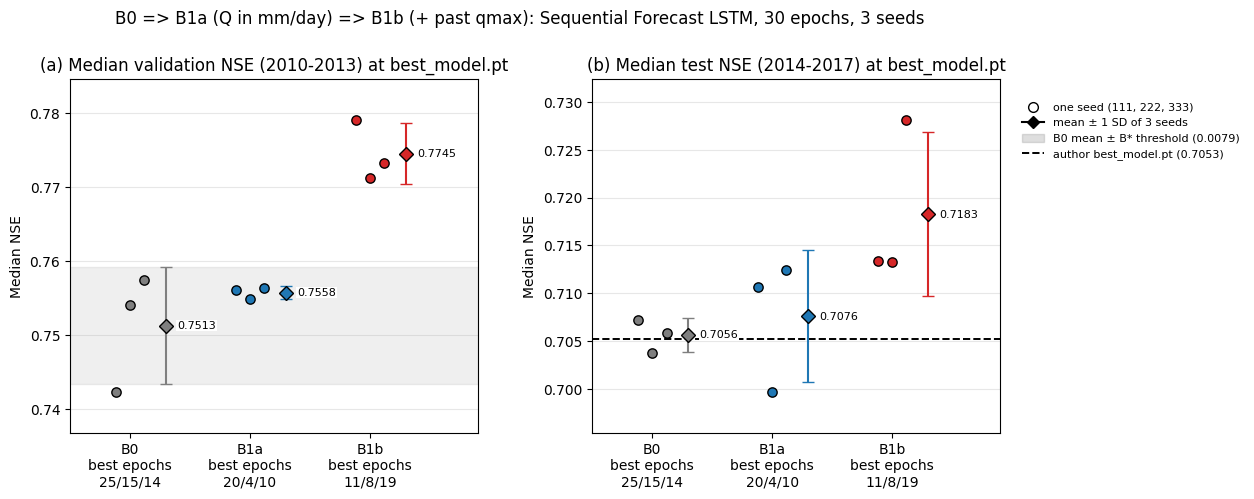

Hình: Mỗi chấm tròn là một hạt giống tại best_model.pt (epoch ghi dưới trục), hình thoi là trung bình ± 1 độ lệch chuẩn 3 hạt giống. (a) NSE trung vị validation - thước đo duy nhất của tầng chọn: trung bình B0, B1a, B1b 0,7513, 0,7558, 0,7745; dải xám là trung bình B0 ± ngưỡng B* 0,0079. Hiệu B1a - B0 0,0045 (trong ngưỡng nhiễu), B1b - B1a 0,0188 (tốt hơn, vượt ngưỡng). (b) NSE trung vị test, chỉ để báo cáo: trung bình 0,7056, 0,7076, 0,7183, nét đứt là best_model.pt của tác giả 0,7053.


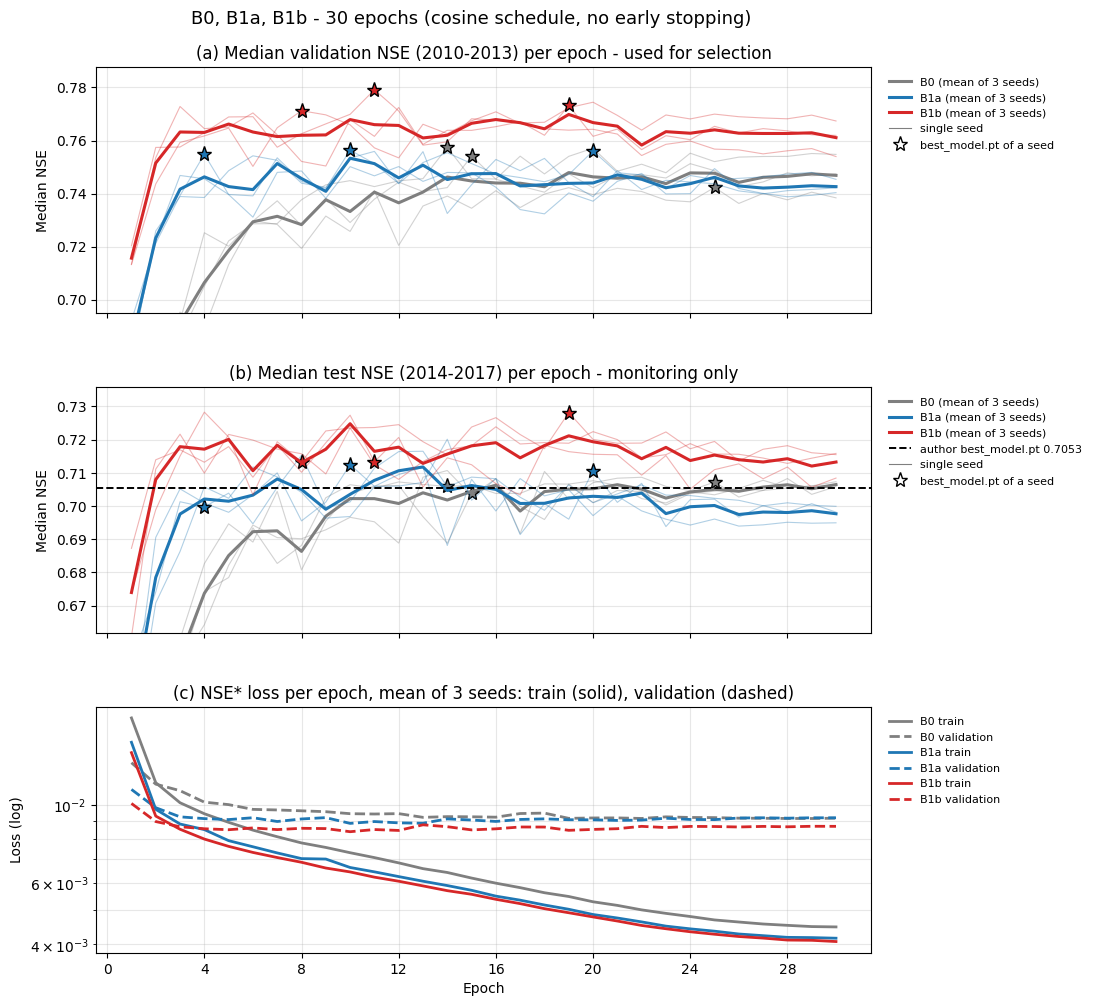

Hình: Nét mảnh: từng hạt giống; nét đậm: trung bình 3 hạt giống; sao: epoch lưu thành best_model.pt. Trục dọc (a), (b) cắt ở phân vị 10% để thấy rõ đoạn sau; ở (a), số epoch đầu của đường trung bình nằm dưới khung: B0 3, B1a 1, B1b 0. (a) Epoch 1 trung bình B0, B1a, B1b đạt 0,6169, 0,6839, 0,7157; đỉnh đường trung bình ở epoch 19, 10, 19; epoch 30 0,7469, 0,7426, 0,7611. (b) NSE trung vị test mỗi epoch, chỉ theo dõi: chọn theo validation thấp hơn epoch test cao nhất trung bình 0,0033, 0,0088, 0,0097; Spearman validation-test qua 30 epoch trung bình 0,72, 0,64, 0,48. (c) Loss NSE* trung bình mỗi epoch: loss huấn luyện epoch 30 0,00449, 0,00417, 0,00408, loss validation 0,00915, 0,00917, 0,00867.


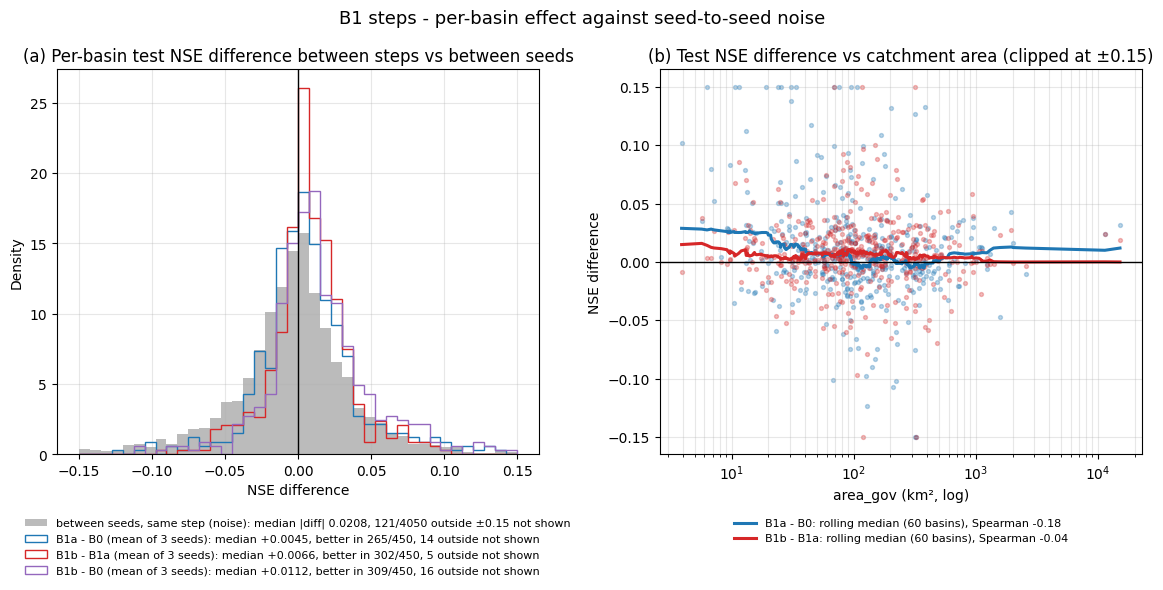

Hình: (a) Phân phối hiệu NSE test theo lưu vực (450 lưu vực), mỗi bước lấy trung bình 3 hạt giống; nền xám là hiệu giữa các cặp hạt giống trong cùng bước (mốc nhiễu, gộp 3 bước), trung vị trị tuyệt đối 0,0208. Hiệu giữa hai trung bình 3 hạt giống ít nhiễu hơn hiệu một cặp hạt giống, nên đọc kèm kiểm định Phần 3: trung vị hiệu B1a - B0 0,0045; B1b - B1a 0,0066; B1b - B0 0,0112. (b) Hiệu theo diện tích area_gov (trục log, chấm bị chặn ở ±0,15), đường là trung vị trượt 60 lưu vực: B1a - B0 (đổi đơn vị Q) trung vị theo 5 nhóm diện tích từ nhỏ tới lớn 0,0198, 0,0065, 0,0008, 0,0023, 0,0003 (Spearman -0,18); B1b - B1a (thêm qmax quá khứ) 0,0046, 0,0069, 0,0084, 0,0065, 0,0036 (Spearman -0,04).
=> Đã lưu 3 hình vào /kaggle/working/b1_compare - chạy Phần 6.


In [5]:
# %% Phần 5 - Hình
# Ba hình thay cho các bảng ở Phần 2-4. Chữ trong hình tiếng Anh, chú giải ngoài vùng vẽ, chú thích tiếng Việt in ngay dưới
# (số dấu phẩy, lấy từ dữ liệu); lưu ở b1_compare/, tải về Workspace/05_Training/05_B1_LamaHCEExt_Compare/Figures/:
#   B1_Steps.png - mỗi bước đạt bao nhiêu tại best_model.pt: (a) NSE trung vị validation (tầng chọn) 3 hạt giống, trung
#     bình ± 1 độ lệch chuẩn, dải B0 ± ngưỡng B*; (b) NSE trung vị test, nét đứt = tác giả;
#   B1_Curves.png - 30 epoch diễn ra thế nào: (a) NSE trung vị validation, (b) NSE trung vị test (chỉ theo dõi), (c) loss
#     huấn luyện và validation theo epoch; nét mảnh = từng hạt giống, nét đậm = trung bình 3 hạt giống, sao = best_model.pt;
#   B1_Effect.png - hiệu theo lưu vực có vượt nhiễu không, nằm ở đâu: (a) phân phối hiệu NSE test theo lưu vực của 3 cặp bước
#     (TB 3 hạt giống) cạnh hiệu giữa các cặp hạt giống; (b) hiệu theo diện tích area_gov (trục log), trung vị trượt.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

STEP_COLORS = {"B0": "#7f7f7f", "B1a": "#1f77b4", "B1b": "#d62728"}
PAIR_COLORS = {"B1a-B0": "#1f77b4", "B1b-B1a": "#d62728", "B1b-B0": "#9467bd"}
NOISE_COLOR = "#bbbbbb"
AUTHOR_STYLE = {"color": "black", "ls": "--", "lw": 1.4}
LEGEND = {"loc": "upper left", "bbox_to_anchor": (1.01, 1), "frameon": False, "fontsize": 8}
DIFF_LIM = 0.15      # trục hiệu NSE từng lưu vực; ngoài khoảng không vẽ, ghi số bị bỏ
ROLL_BASINS = 60     # cửa sổ trung vị trượt theo diện tích (số lưu vực)


def caption(text):
    print(f"Hình: {text}")


def vn(x, digits=4):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


def save(fig, name):
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


# Kỳ validation, test lấy từ config.yml của run (thư viện ghi dd/mm/YYYY, một giá trị hoặc danh sách - lấy năm đầu, cuối)
cfg0 = read_config("B0", SEEDS[0])


def period_years(name):
    start, end = cfg0[f"{name}_start_date"], cfg0[f"{name}_end_date"]
    start, end = (start[0] if isinstance(start, list) else start), (end[-1] if isinstance(end, list) else end)
    return f"{str(start)[-4:]}-{str(end)[-4:]}"


VAL_YEARS, TEST_YEARS = period_years("validation"), period_years("test")
STEP_LIST = list(RUNS)

# Hình 1 - 3 bước tại best_model.pt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"wspace": 0.28})
for ax, col, name, years in [(ax1, "NSE trung vị validation", "validation", VAL_YEARS),
                             (ax2, "NSE trung vị test", "test", TEST_YEARS)]:
    if name == "validation":
        m0 = st_idx.loc[("B0", col), "trung bình"]
        ax.axhspan(m0 - BSTAR_SD, m0 + BSTAR_SD, color=STEP_COLORS["B0"], alpha=0.12)
    else:
        ax.axhline(AUTHOR_NSE, **AUTHOR_STYLE)
    for k, st in enumerate(STEP_LIST):
        v = step_values(st, col)
        m, sd_ = st_idx.loc[(st, col), "trung bình"], st_idx.loc[(st, col), "độ lệch chuẩn (ddof=1)"]
        ax.scatter(k + np.array([-0.12, 0, 0.12]), v.values, s=45, color=STEP_COLORS[st], edgecolor="black", zorder=3)
        ax.errorbar(k + 0.3, m, yerr=sd_, fmt="D", ms=7, color=STEP_COLORS[st], mec="black", capsize=4, zorder=3)
        ax.annotate(f"{m:.4f}", (k + 0.3, m), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8,
                    bbox={"fc": "white", "ec": "none", "pad": 0.5}, zorder=4)
    ax.set(title=f"({'ab'[name == 'test']}) Median {name} NSE ({years}) at best_model.pt", xticks=range(len(STEP_LIST)),
           xticklabels=[f"{st}\nbest epochs\n{'/'.join(str(BEST[st][s]) for s in SEEDS)}" for st in STEP_LIST],
           ylabel="Median NSE", xlim=(-0.5, len(STEP_LIST) - 0.1))
    ax.margins(y=0.15)
    ax.grid(alpha=0.3, axis="y")
fig.legend(handles=[Line2D([], [], marker="o", color="white", mec="black", ms=7, label="one seed (111, 222, 333)"),
                    Line2D([], [], marker="D", color="black", ms=6, label="mean ± 1 SD of 3 seeds"),
                    Patch(color=STEP_COLORS["B0"], alpha=0.25, label=f"B0 mean ± B* threshold ({BSTAR_SD:.4f})"),
                    Line2D([], [], **AUTHOR_STYLE, label=f"author best_model.pt ({AUTHOR_NSE:.4f})")],
           loc="upper left", bbox_to_anchor=(0.91, 0.85), frameon=False, fontsize=8)
fig.suptitle("B0 => B1a (Q in mm/day) => B1b (+ past qmax): Sequential Forecast LSTM, 30 epochs, 3 seeds", fontsize=12, y=1.03)
save(fig, "B1_Steps.png")
sd_txt = STEP_DELTA.set_index("cặp")
caption(f"Mỗi chấm tròn là một hạt giống tại best_model.pt (epoch ghi dưới trục), hình thoi là trung bình ± 1 độ lệch chuẩn "
        f"3 hạt giống. (a) NSE trung vị validation - thước đo duy nhất của tầng chọn: trung bình B0, B1a, B1b "
        f"{', '.join(vn(st_idx.loc[(st, 'NSE trung vị validation'), 'trung bình']) for st in STEP_LIST)}; dải xám là trung "
        f"bình B0 ± ngưỡng B* {vn(BSTAR_SD)}. Hiệu B1a - B0 {vn(sd_txt.loc['B1a - B0', 'Δ NSE validation (TB 3 hạt giống)'])} "
        f"({sd_txt.loc['B1a - B0', 'kết luận tầng chọn']}), B1b - B1a "
        f"{vn(sd_txt.loc['B1b - B1a', 'Δ NSE validation (TB 3 hạt giống)'])} ({sd_txt.loc['B1b - B1a', 'kết luận tầng chọn']}). "
        f"(b) NSE trung vị test, chỉ để báo cáo: trung bình "
        f"{', '.join(vn(st_idx.loc[(st, 'NSE trung vị test'), 'trung bình']) for st in STEP_LIST)}, nét đứt là best_model.pt "
        f"của tác giả {vn(AUTHOR_NSE)}.")

# Hình 2 - 30 epoch
fig, axes = plt.subplots(3, 1, figsize=(10, 11.5), sharex=True, gridspec_kw={"hspace": 0.3})
for st in STEP_LIST:
    col = STEP_COLORS[st]
    for ax, key in [(axes[0], VAL_COL), (axes[1], TEST_COL)]:
        for s in SEEDS:
            c = CURVES[st][s]
            ax.plot(c.index, c[key], lw=0.8, alpha=0.35, color=col)
            ax.plot(BEST[st][s], c.loc[BEST[st][s], key], "*", ms=11, color=col, mec="black", ls="none")
        short_key = CURVE_COLS[key]
        ax.plot(CURVE_MEAN.index, CURVE_MEAN[f"{st} {short_key}"], lw=2.2, color=col, label=f"{st} (mean of 3 seeds)")
    axes[2].plot(CURVE_MEAN.index, CURVE_MEAN[f"{st} loss train"], lw=2, color=col, label=f"{st} train")
    axes[2].plot(CURVE_MEAN.index, CURVE_MEAN[f"{st} loss val"], lw=2, ls="--", color=col, label=f"{st} validation")
axes[1].axhline(AUTHOR_NSE, **AUTHOR_STYLE, label=f"author best_model.pt {AUTHOR_NSE:.4f}")
axes[2].set_yscale("log")
marks = [Line2D([], [], lw=0.8, alpha=0.5, color="black", label="single seed"),
         Line2D([], [], marker="*", ms=11, color="white", mec="black", ls="none", label="best_model.pt of a seed")]
axes[0].set(title=f"(a) Median validation NSE ({VAL_YEARS}) per epoch - used for selection", ylabel="Median NSE")
axes[1].set(title=f"(b) Median test NSE ({TEST_YEARS}) per epoch - monitoring only", ylabel="Median NSE")
axes[2].set(title="(c) NSE* loss per epoch, mean of 3 seeds: train (solid), validation (dashed)", xlabel="Epoch",
            ylabel="Loss (log)")
for ax in axes:
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3, which="both" if ax is axes[2] else "major")
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles=handles + (marks if ax is not axes[2] else []), **LEGEND)
for ax, k in [(axes[0], "NSE val"), (axes[1], "NSE test")]:
    ax.set_ylim(bottom=min(CURVE_MEAN[f"{st} {k}"].quantile(0.1) for st in STEP_LIST) - 0.01)
cut = axes[0].get_ylim()[0]
below = {st: int((CURVE_MEAN[f"{st} NSE val"] < cut).sum()) for st in STEP_LIST}
fig.suptitle("B0, B1a, B1b - 30 epochs (cosine schedule, no early stopping)", fontsize=13, y=0.93)
save(fig, "B1_Curves.png")
peak = EPOCH_PEAKS[EPOCH_PEAKS["hạt giống"].isna()].set_index("bước")
seed_peak = EPOCH_PEAKS[EPOCH_PEAKS["hạt giống"].notna()]
caption(f"Nét mảnh: từng hạt giống; nét đậm: trung bình 3 hạt giống; sao: epoch lưu thành best_model.pt. Trục dọc (a), (b) "
        f"cắt ở phân vị 10% để thấy rõ đoạn sau; ở (a), số epoch đầu của đường trung bình nằm dưới khung: "
        f"{', '.join(f'{st} {n}' for st, n in below.items())}. (a) Epoch 1 trung bình B0, B1a, B1b đạt "
        f"{', '.join(vn(CURVE_MEAN[f'{st} NSE val'].iloc[0]) for st in STEP_LIST)}; đỉnh đường trung bình ở epoch "
        f"{', '.join(str(peak.loc[f'{st} (đường TB)', 'epoch best_model.pt']) for st in STEP_LIST)}; epoch 30 "
        f"{', '.join(vn(CURVE_MEAN[f'{st} NSE val'].iloc[-1]) for st in STEP_LIST)}. (b) NSE trung vị test mỗi epoch, chỉ "
        f"theo dõi: chọn theo validation thấp hơn epoch test cao nhất trung bình "
        f"{', '.join(vn(-g['mất do chọn theo val'].mean()) for _, g in seed_peak.groupby('bước', sort=False))}; Spearman "
        f"validation-test qua 30 epoch trung bình "
        f"{', '.join(vn(g['Spearman val-test qua epoch'].mean(), 2) for _, g in seed_peak.groupby('bước', sort=False))}. "
        f"(c) Loss NSE* trung bình mỗi epoch: loss huấn luyện epoch 30 "
        f"{', '.join(vn(CURVE_MEAN[f'{st} loss train'].iloc[-1], 5) for st in STEP_LIST)}, loss validation "
        f"{', '.join(vn(CURVE_MEAN[f'{st} loss val'].iloc[-1], 5) for st in STEP_LIST)}.")

# Hình 3 - hiệu theo lưu vực so với nhiễu, theo diện tích
noise_all = pd.concat(noise.values())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"wspace": 0.25})
bins = np.linspace(-DIFF_LIM, DIFF_LIM, 41)
ax1.hist(noise_all[noise_all.abs() <= DIFF_LIM], bins=bins, density=True, color=NOISE_COLOR,
         label=f"between seeds, same step (noise): median |diff| {noise_all.abs().median():.4f}, "
               f"{int((noise_all.abs() > DIFF_LIM).sum())}/{len(noise_all)} outside ±{DIFF_LIM:g} not shown")
for new, old, _ in STEP_PAIRS:
    d = BASIN_NSE[f"Δ {new}-{old}"]
    ax1.hist(d[d.abs() <= DIFF_LIM], bins=bins, density=True, histtype="step", lw=1.8, color=PAIR_COLORS[f"{new}-{old}"],
             label=f"{new} - {old} (mean of 3 seeds): median {d.median():+.4f}, better in {int((d > 0).sum())}/{len(d)}, "
                   f"{int((d.abs() > DIFF_LIM).sum())} outside not shown")
ax1.axvline(0, color="black", lw=1)
ax1.set(title="(a) Per-basin test NSE difference between steps vs between seeds", xlabel="NSE difference",
        ylabel="Density")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False, fontsize=8)
by_area = BASIN_NSE.sort_values("diện tích (km²)")
for new, old in [("B1a", "B0"), ("B1b", "B1a")]:
    key, col = f"Δ {new}-{old}", PAIR_COLORS[f"{new}-{old}"]
    d = by_area[key].clip(-DIFF_LIM, DIFF_LIM)
    rho = SPEARMAN.set_index("hiệu").loc[key, "rho Spearman"]
    ax2.scatter(by_area["diện tích (km²)"], d, s=8, alpha=0.3, color=col)
    ax2.plot(by_area["diện tích (km²)"], by_area[key].rolling(ROLL_BASINS, center=True, min_periods=ROLL_BASINS // 2)
             .median(), lw=2.2, color=col, label=f"{new} - {old}: rolling median ({ROLL_BASINS} basins), Spearman {rho:+.2f}")
ax2.axhline(0, color="black", lw=1)
ax2.set_xscale("log")
ax2.set(title=f"(b) Test NSE difference vs catchment area (clipped at ±{DIFF_LIM:g})", xlabel="area_gov (km², log)",
        ylabel="NSE difference")
ax2.grid(alpha=0.3, which="both")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False, fontsize=8)
fig.suptitle("B1 steps - per-basin effect against seed-to-seed noise", fontsize=13, y=1.0)
save(fig, "B1_Effect.png")
area_tab = BY_AREA.set_index("nhóm diện tích")
caption(f"(a) Phân phối hiệu NSE test theo lưu vực ({len(BASIN_NSE)} lưu vực), mỗi bước lấy trung bình 3 hạt giống; nền xám "
        f"là hiệu giữa các cặp hạt giống trong cùng bước (mốc nhiễu, gộp 3 bước), trung vị trị tuyệt đối "
        f"{vn(noise_all.abs().median())}. Hiệu giữa hai trung bình 3 hạt giống ít nhiễu hơn hiệu một cặp hạt giống, nên "
        f"đọc kèm kiểm định Phần 3: trung vị hiệu "
        + "; ".join(f"{new} - {old} {vn(BASIN_NSE[f'Δ {new}-{old}'].median())}" for new, old, _ in STEP_PAIRS)
        + f". (b) Hiệu theo diện tích area_gov (trục log, chấm bị chặn ở ±{vn(DIFF_LIM, 2)}), đường là trung vị trượt "
        f"{ROLL_BASINS} lưu vực: B1a - B0 (đổi đơn vị Q) trung vị theo 5 nhóm diện tích từ nhỏ tới lớn "
        f"{', '.join(vn(v) for v in area_tab['trung vị Δ B1a-B0'])} (Spearman "
        f"{vn(SPEARMAN.set_index('hiệu').loc['Δ B1a-B0', 'rho Spearman'], 2)}); B1b - B1a (thêm qmax quá khứ) "
        f"{', '.join(vn(v) for v in area_tab['trung vị Δ B1b-B1a'])} (Spearman "
        f"{vn(SPEARMAN.set_index('hiệu').loc['Δ B1b-B1a', 'rho Spearman'], 2)}).")
print("=> Đã lưu 3 hình vào", OUT_DIR, "- chạy Phần 6.")


# Phần 6 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
 Mỗi run B1a, B1b một tệp SeqLSTM_Q_<bước>_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
 01_Evaluation_LamaHCEExt.md Mục 7, chép cách dựng của B0 Compare Phần 6 (3 NPZ B0 đã giao ở Output notebook đó, không dựng
 lại): sim thô lấy từ test_results.p của best_model.pt (["1D"]["xr"]["qmax_sim"], time_step = 0, chưa chặn âm - tester.py
 dòng 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của config.yml. obs, persistence, diện tích,
 thứ tự ID lấy nguyên từ ngữ cảnh A3 (như read_context của bộ đánh giá, Phần 8.1) vì bộ đánh giá đòi bằng nhau từng bit
 giữa các run cùng nhóm (check_same_context). library_commit là commit bước B (f229e02), selected_epoch là epoch
 best_model.pt sau 30 epoch. Kiểm lại: (1) đọc ngược tệp theo đúng các điều kiện của read_contract (Phần 8.3) và
 check_same_context; (2) NSE từng lưu vực tính lại khớp test_metrics.csv của thư viện; (3) obs riêng của run trùng mặt nạ
 và giá trị với obs A3 (đổi đơn vị Q đầu vào không được đổi nhãn qmax).

In [6]:
# %% Phần 6 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
# Mỗi run B1a, B1b một tệp SeqLSTM_Q_<bước>_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
# 01_Evaluation_LamaHCEExt.md Mục 7, chép cách dựng của B0 Compare Phần 6 (3 NPZ B0 đã giao ở Output notebook đó, không dựng
# lại): sim thô lấy từ test_results.p của best_model.pt (["1D"]["xr"]["qmax_sim"], time_step = 0, chưa chặn âm - tester.py
# dòng 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của config.yml. obs, persistence, diện tích,
# thứ tự ID lấy nguyên từ ngữ cảnh A3 (như read_context của bộ đánh giá, Phần 8.1) vì bộ đánh giá đòi bằng nhau từng bit
# giữa các run cùng nhóm (check_same_context). library_commit là commit bước B (f229e02), selected_epoch là epoch
# best_model.pt sau 30 epoch. Kiểm lại: (1) đọc ngược tệp theo đúng các điều kiện của read_contract (Phần 8.3) và
# check_same_context; (2) NSE từng lưu vực tính lại khớp test_metrics.csv của thư viện; (3) obs riêng của run trùng mặt nạ
# và giá trị với obs A3 (đổi đơn vị Q đầu vào không được đổi nhãn qmax).
import pickle

CONTRACT_DIR = OUT_DIR / "contracts"
CONTRACT_DIR.mkdir(exist_ok=True)
CONTRACT_STEPS = ["B1a", "B1b"]
CONTRACT_KEYS = ("run", "period", "scenario", "lead", "forecast_horizon", "seed", "unit", "config_sha256",
                 "library_commit", "clip_to_zero")
NSE_TOL = 1e-5  # NSE tính lại (float64) so với test_metrics.csv của thư viện
TEST_DATES = pd.date_range(pd.to_datetime(str(cfg0["test_start_date"]), dayfirst=True),
                           pd.to_datetime(str(cfg0["test_end_date"]), dayfirst=True))


def basin_id(value):
    return str(int(str(value).strip()))


def contract_name(step, seed):
    return f"SeqLSTM_Q_{step}_seed{seed}"


# (1) Ngữ cảnh A3 - như read_context của bộ đánh giá
with np.load(A3_PATHS["A3_persistence_predictions.npz"], allow_pickle=False) as d:
    CTX_DATES = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_IDS = tuple(basin_id(x) for x in d["basin_ids"])
    CTX_OBS = np.array(d["obs_source_mm_day"], dtype=float)
    CTX_PERS = np.array(d["persistence_qmax_mm_day"], dtype=float)
    src_ok = np.array_equal(d["source_dates"], d["dates"] - np.timedelta64(1, "D"))
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    q_ids = tuple(basin_id(x) for x in d["basin_ids"])
    q_dates = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_AREA = np.array(d["area_gov_km2"], dtype=float)
    q = np.array(d["qmax_numeric_m3_s"], dtype=float)
q[q < 0] = np.nan
physical = q * 86.4 / CTX_AREA[None, :]
ctx_checks = [(f"Lịch test {TEST_YEARS} theo config.yml", CTX_DATES.equals(TEST_DATES.as_unit("ns"))),
              ("Ngày nguồn persistence = ngày đích - 1", src_ok),
              ("ID nguồn Q trùng ID persistence", q_ids == CTX_IDS),
              ("Lịch nguồn Q bắt đầu trước kỳ test 1 ngày",
               q_dates.equals(pd.date_range(TEST_DATES[0] - pd.Timedelta(days=1), TEST_DATES[-1]).as_unit("ns"))),
              ("obs, persistence khớp Q gốc / diện tích",
               np.allclose(CTX_OBS, physical[1:], rtol=1e-12, atol=1e-12, equal_nan=True)
               and np.allclose(CTX_PERS, physical[:-1], rtol=1e-12, atol=1e-12, equal_nan=True)),
              ("Đủ 451 ID", len(CTX_IDS) == 451)]
show(f"Ngữ cảnh A3 ({len(CTX_DATES)} ngày x {len(CTX_IDS)} lưu vực)",
     pd.DataFrame([{"mục": a, "đạt": "ĐẠT" if b else "KHÔNG"} for a, b in ctx_checks]))
if not all(b for _, b in ctx_checks):
    raise RuntimeError(f"Phần 6 CHƯA đạt: ngữ cảnh A3 sai - kiểm Input A3 Version {A3_VERSION}")


def check_contract(path):
    # Các điều kiện của read_contract (Phần 8.3) + check_same_context (Phần 2.1) với ngữ cảnh A3; trả danh sách lỗi.
    errs = []
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        if any(k not in meta for k in CONTRACT_KEYS) or meta.get("unit") != "mm/day_area_gov":
            errs.append("thiếu metadata hoặc sai đơn vị")
        if not isinstance(meta.get("clip_to_zero"), bool):
            errs.append("clip_to_zero không phải bool")
        lead, hz = meta.get("lead"), meta.get("forecast_horizon")
        if not (isinstance(lead, int) and isinstance(hz, int) and 1 <= lead <= hz <= 7):
            errs.append("sai lead/forecast_horizon")
        dates = np.array(d["dates"], dtype="datetime64[D]")
        if (not np.array_equal(d["origin_dates"], dates - np.timedelta64(lead - 1, "D"))
                or not np.array_equal(d["persistence_source_dates"], dates - np.timedelta64(lead, "D"))):
            errs.append("sai origin/persistence_source_dates")
        raw, sim = np.array(d["sim_raw_mm_day"], dtype=float), np.array(d["sim_mm_day"], dtype=float)
        if not np.array_equal(sim, np.maximum(raw, 0) if meta.get("clip_to_zero") else raw, equal_nan=True):
            errs.append("sim khác chính sách chặn âm")
        if np.isinf(sim).any() or np.isinf(raw).any() or sim.shape != (len(CTX_DATES), len(CTX_IDS)):
            errs.append("sim sai kích thước hoặc có vô cực")
        if (not pd.DatetimeIndex(dates).as_unit("ns").equals(CTX_DATES)
                or tuple(basin_id(x) for x in d["basin_ids"]) != CTX_IDS
                or not np.array_equal(d["area_gov_km2"], CTX_AREA)):
            errs.append("khác lịch, ID hoặc diện tích ngữ cảnh A3")
        for k, ref in (("obs_mm_day", CTX_OBS), ("persistence_mm_day", CTX_PERS)):
            if not np.array_equal(d[k], ref, equal_nan=True):
                errs.append(f"{k} khác ngữ cảnh A3")
    return errs


def nse_basin(obs, sim):
    ok = np.isfinite(obs) & np.isfinite(sim)
    o, s = obs[ok], sim[ok]
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2) if len(o) > 1 else np.nan


# (2) Dựng và kiểm từng run
rows, CONTRACT_PATHS = [], {}
target = CTX_DATES.to_numpy().astype("datetime64[D]")
for st in CONTRACT_STEPS:
    for s in SEEDS:
        cfg_path = run_dir(st, s) / "config.yml"
        clip = yaml.safe_load(cfg_path.read_text(encoding="utf-8-sig")).get("clip_targets_to_zero", []) or []
        clip = [clip] if isinstance(clip, str) else clip
        # test_results.p là pickle do chính notebook hạt giống ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
        with (run_dir(st, s) / "test" / "best_model" / "test_results.p").open("rb") as fp:
            saved = pickle.load(fp)
        keys = {basin_id(k): k for k in saved}
        if len(keys) != len(saved) or set(keys) != set(CTX_IDS):
            raise RuntimeError(f"{st} hạt giống {s}: ID trong test_results.p thiếu, thừa hoặc trùng")
        native, raw = np.full_like(CTX_OBS, np.nan), np.full_like(CTX_OBS, np.nan)
        for j, b in enumerate(CTX_IDS):
            xr_ = saved[keys[b]]["1D"]["xr"]
            if (not np.array_equal(xr_["time_step"].values, [0])
                    or not pd.DatetimeIndex(xr_["date"].values).as_unit("ns").equals(CTX_DATES)):
                raise RuntimeError(f"{st} hạt giống {s}, lưu vực {b}: time_step khác [0] hoặc lịch khác kỳ test")
            native[:, j] = xr_["qmax_obs"].transpose("date", "time_step").values[:, 0]
            raw[:, j] = xr_["qmax_sim"].transpose("date", "time_step").values[:, 0]
        sim = np.maximum(raw, 0) if "qmax" in clip else raw.copy()
        name = contract_name(st, s)
        meta = {"run": name, "period": "test", "scenario": "S0", "lead": 1, "forecast_horizon": 1, "seed": s,
                "unit": "mm/day_area_gov", "config_sha256": sha256(cfg_path),
                "library_commit": ENVS[st][s]["neuralhydrology_commit"], "clip_to_zero": "qmax" in clip,
                "selected_epoch": BEST[st][s],
                "source": f"{RUNS[st]['notebook'].format(s)} Version {VERSIONS[st][s]}, "
                          f"{ENVS[st][s]['run_dir']}/test/best_model/test_results.p"}
        path = CONTRACT_DIR / f"{name}_test_S0_lead1.npz"
        np.savez_compressed(path, dates=target, origin_dates=target,
                            persistence_source_dates=target - np.timedelta64(1, "D"), basin_ids=np.array(CTX_IDS),
                            area_gov_km2=CTX_AREA, obs_mm_day=CTX_OBS, persistence_mm_day=CTX_PERS, sim_raw_mm_day=raw,
                            sim_mm_day=sim, metadata_json=json.dumps(meta))
        CONTRACT_PATHS[(st, s)] = path

        # Kiểm: hợp đồng, NSE so với thư viện, obs riêng của run so với A3
        errs = check_contract(path)
        lib = TEST_METRICS[st][s]["NSE"].reindex(list(CTX_IDS)).to_numpy(dtype=float)
        mine = np.array([nse_basin(native[:, j], sim[:, j]) for j in range(len(CTX_IDS))])
        both = np.isfinite(lib) & np.isfinite(mine)
        nse_diff = float(np.max(np.abs(lib[both] - mine[both]))) if both.any() else np.nan
        nan_same = np.array_equal(np.isfinite(lib), np.isfinite(mine))
        mask_same = np.array_equal(np.isfinite(native), np.isfinite(CTX_OBS))
        both_obs = np.isfinite(native) & np.isfinite(CTX_OBS)
        rows.append({"bước": st, "hạt giống": s, "tệp": path.name, "MB": path.stat().st_size / 1e6,
                     "selected_epoch": BEST[st][s], "clip_to_zero": meta["clip_to_zero"],
                     "dự báo âm trước chặn": int((raw < 0).sum()), "ngày-lưu vực có sim": int(np.isfinite(sim).sum()),
                     "lỗi hợp đồng": "; ".join(errs) or "-", "max |ΔNSE| so với thư viện": nse_diff,
                     "NaN NSE trùng thư viện": nan_same, "mặt nạ obs trùng A3": mask_same,
                     "max |obs run - obs A3|": float(np.max(np.abs(native[both_obs] - CTX_OBS[both_obs]))),
                     "NSE trung vị từ NPZ": float(np.nanmedian(mine)),
                     "đạt": not errs and nse_diff <= NSE_TOL and nan_same and mask_same})
CONTRACT_TABLE = pd.DataFrame(rows)
show("Hợp đồng NPZ cho bộ đánh giá (kiểm đọc ngược và NSE tính lại)", CONTRACT_TABLE, digits=6)
if not CONTRACT_TABLE["đạt"].all():
    raise RuntimeError(f"Phần 6 CHƯA đạt (cột 'đạt' = False ở trên; ngưỡng NSE {NSE_TOL})")
print(f"=> Đạt. {len(CONTRACT_PATHS)} tệp ở {CONTRACT_DIR}; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 7.")


mục,đạt
Lịch test 2014-2017 theo config.yml,ĐẠT
Ngày nguồn persistence = ngày đích - 1,ĐẠT
ID nguồn Q trùng ID persistence,ĐẠT
Lịch nguồn Q bắt đầu trước kỳ test 1 ngày,ĐẠT
"obs, persistence khớp Q gốc / diện tích",ĐẠT
Đủ 451 ID,ĐẠT


bước,hạt giống,tệp,MB,selected_epoch,clip_to_zero,dự báo âm trước chặn,ngày-lưu vực có sim,lỗi hợp đồng,max |ΔNSE| so với thư viện,NaN NSE trùng thư viện,mặt nạ obs trùng A3,max |obs run - obs A3|,NSE trung vị từ NPZ,đạt
B1a,111,SeqLSTM_Q_B1a_seed111_test_S0_lead1.npz,9.977192,20,True,811,652644,-,0.000000,True,True,0.000011,0.710672,True
B1a,222,SeqLSTM_Q_B1a_seed222_test_S0_lead1.npz,9.974168,4,True,2148,652644,-,0.000001,True,True,0.000011,0.699695,True
B1a,333,SeqLSTM_Q_B1a_seed333_test_S0_lead1.npz,9.980752,10,True,3057,652644,-,0.000000,True,True,0.000011,0.712467,True
B1b,111,SeqLSTM_Q_B1b_seed111_test_S0_lead1.npz,9.962006,11,True,4036,652644,-,0.000000,True,True,0.000011,0.713339,True
B1b,222,SeqLSTM_Q_B1b_seed222_test_S0_lead1.npz,9.982399,8,True,1765,652644,-,0.000001,True,True,0.000011,0.713279,True
B1b,333,SeqLSTM_Q_B1b_seed333_test_S0_lead1.npz,9.978237,19,True,3766,652644,-,0.000000,True,True,0.000011,0.728158,True


=> Đạt. 6 tệp ở /kaggle/working/b1_compare/contracts; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 7.


# Phần 7 - Lưu kết quả và môi trường
 Lưu các bảng còn lại của Phần 2, 3, 6, tóm tắt B1 (b1_summary.json - số liệu dùng cho báo cáo B1a, B1b và luật B*),
 environment.json (Input đã gắn, phiên bản notebook nguồn, thư viện) và manifest.csv (mọi tệp trong b1_compare kèm sha256
 để bước sau kiểm khi gắn Output này làm Input). Bảng Phần 3, 4 đã lưu ở phần đó, hình ở Phần 5, NPZ ở Phần 6.

In [7]:
# %% Phần 7 - Lưu kết quả và môi trường
# Lưu các bảng còn lại của Phần 2, 3, 6, tóm tắt B1 (b1_summary.json - số liệu dùng cho báo cáo B1a, B1b và luật B*),
# environment.json (Input đã gắn, phiên bản notebook nguồn, thư viện) và manifest.csv (mọi tệp trong b1_compare kèm sha256
# để bước sau kiểm khi gắn Output này làm Input). Bảng Phần 3, 4 đã lưu ở phần đó, hình ở Phần 5, NPZ ở Phần 6.
SEED_TABLE.to_csv(OUT_DIR / "B1_seed_table.csv", index=False)
STATS.to_csv(OUT_DIR / "B1_seed_stats.csv", index=False)
STEP_DELTA.to_csv(OUT_DIR / "B1_step_delta.csv", index=False)
TIMING.to_csv(OUT_DIR / "B1_timing.csv", index=False)
NOISE.to_csv(OUT_DIR / "B1_seed_noise.csv", index=False)
SPEARMAN.to_csv(OUT_DIR / "B1_area_spearman.csv", index=False)
CONTRACT_TABLE.to_csv(OUT_DIR / "B1_contracts.csv", index=False)


def paired_summary(r):
    return {"median_diff": float(r["trung vị hiệu"]), "mean_diff": float(r["trung bình hiệu"]),
            "better_basins": int(r["trái tốt hơn"]), "basins": int(r["số cặp"]), "cohen_dz": float(r["Cohen's dz"]),
            "p_holm": float(r["p Holm"])}


def pair_key(r):
    return f"{r['trái']}-{r['phải']}".replace(" TB", "").replace(" ", "_")


seed_peaks = EPOCH_PEAKS[EPOCH_PEAKS["hạt giống"].notna()].set_index(["bước", "hạt giống"])
B1_SUMMARY = {
    "bstar_threshold_val_nse_sd": BSTAR_SD, "author_test_nse_median": AUTHOR_NSE,
    "seed_val_nse_median": {st: {s: float(step_values(st, "NSE trung vị validation")[s]) for s in SEEDS} for st in RUNS},
    "seed_test_nse_median": {st: {s: float(step_values(st, "NSE trung vị test")[s]) for s in SEEDS} for st in RUNS},
    "step_mean_sd": {st: {c: [float(st_idx.loc[(st, c), "trung bình"]), float(st_idx.loc[(st, c), "độ lệch chuẩn (ddof=1)"])]
                          for c in ["NSE trung vị validation", "NSE trung vị test"]} for st in RUNS},
    "step_delta": {r["cặp"]: {"val_nse_mean_diff": float(r["Δ NSE validation (TB 3 hạt giống)"]),
                              "ratio_to_bstar": float(r["Δ / ngưỡng B*"]), "verdict": r["kết luận tầng chọn"],
                              "test_nse_mean_diff": float(r["Δ NSE test (TB 3 hạt giống)"])} for _, r in STEP_DELTA.iterrows()},
    "saved_epoch": BEST,
    "paired_tests": {f"{kind}/{fam[:3]}": {pair_key(r): paired_summary(r) for _, r in g.iterrows()}
                     for (kind, fam), g in PAIRED.groupby(["kỳ", "họ"], sort=False)},
    "basins_compared": len(BASIN_NSE),
    "seed_noise_abs_median": {st: float(v.abs().median()) for st, v in noise.items()},
    "by_area_median_diff": {c: [float(v) for v in BY_AREA[f"trung vị {c}"]] for c in delta_cols},
    "area_group_median_km2": [float(v) for v in BY_AREA["diện tích trung vị (km²)"]],
    "area_spearman": {r["hiệu"]: {"rho": float(r["rho Spearman"]), "p": float(r["p"])} for _, r in SPEARMAN.iterrows()},
    "per_epoch": {st: {"val_epoch1_mean": float(CURVE_MEAN[f"{st} NSE val"].iloc[0]),
                       "val_epoch30_mean": float(CURVE_MEAN[f"{st} NSE val"].iloc[-1]),
                       "mean_curve_peak_epoch": int(CURVE_MEAN[f"{st} NSE val"].idxmax()),
                       "loss_from_val_selection": {s: float(seed_peaks.loc[(st, s), "mất do chọn theo val"]) for s in SEEDS},
                       "spearman_val_test": {s: float(seed_peaks.loc[(st, s), "Spearman val-test qua epoch"]) for s in SEEDS},
                       "val_drop_after_best": {s: float(seed_peaks.loc[(st, s), "giảm val sau best"]) for s in SEEDS}}
                  for st in RUNS},
    "train_hours": {st: {s: SUMMARY[st][s]["train_hours"] for s in SEEDS} for st in RUNS},
    "contracts": {f"{st}_{s}": p.relative_to(WORK_DIR).as_posix() for (st, s), p in CONTRACT_PATHS.items()}}
(OUT_DIR / "b1_summary.json").write_text(json.dumps(B1_SUMMARY, ensure_ascii=False, indent=2), encoding="utf-8")

env = {"notebook": "05_B1_LamaHCEExt_Compare", "env": {k: str(v) for k, v in ENV.items()},
       "inputs": {st: {s: {"notebook": RUNS[st]["notebook"].format(s), "version": VERSIONS[st][s],
                           "input_dir": short(ROOTS[st][s]), "run_dir": ENVS[st][s]["run_dir"]} for s in SEEDS}
                  for st in RUNS}
                 | {"a3": {"notebook": "02_A3_LamaHCEExt_Benchmarks", "version": A3_VERSION,
                           "files": {n: {"path": short(p), "sha256": sha256(p)} for n, p in A3_PATHS.items()}},
                    "author_test_metrics": {"path": short(AUTHOR_METRICS_PATH), "sha256": sha256(AUTHOR_METRICS_PATH)}},
       "neuralhydrology_commit_of_runs": COMMIT}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
MANIFEST = pd.DataFrame([{"tệp": p.relative_to(OUT_DIR).as_posix(), "KB": p.stat().st_size / 1e3, "sha256": sha256(p)}
                         for p in files])
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show(f"Output trong {OUT_DIR.relative_to(WORK_DIR)}/ ({len(MANIFEST)} tệp, {MANIFEST['KB'].sum() / 1e3:.1f} MB)",
     MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12]), digits=1)
expected = {f"B1_{n}.csv" for n in ["seed_table", "seed_stats", "step_delta", "timing", "seed_noise", "area_spearman",
                                    "contracts", "paired_tests", "basin_nse", "by_nse_level", "by_area", "curves_mean",
                                    "epoch_peaks"]} | {
            "B1_Steps.png", "B1_Curves.png", "B1_Effect.png", "b1_summary.json", "environment.json"} | {
            f"contracts/{p.name}" for p in CONTRACT_PATHS.values()}
missing, extra = sorted(expected - set(MANIFEST["tệp"])), sorted(set(MANIFEST["tệp"]) - expected)
if missing:
    raise RuntimeError(f"Phần 7 CHƯA đạt: thiếu {missing}")
if extra:
    print(f"Lưu ý: có tệp ngoài danh sách (thường do chạy tương tác bản cũ, Save & Run All sẽ không có): {extra}")
print("=> Xong B1. Tải 3 hình B1_Steps.png, B1_Curves.png, B1_Effect.png về "
      "Workspace/05_Training/05_B1_LamaHCEExt_Compare/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá.")


tệp,KB,sha256
B1_Curves.png,475.0,be33c468d417
B1_Effect.png,220.1,344e41d31cbe
B1_Steps.png,116.1,f8c1aa8ad5b3
B1_area_spearman.csv,0.2,cf46a5869ece
B1_basin_nse.csv,183.7,69b72f84cada
B1_by_area.csv,0.6,0c2699a6d9c3
B1_by_nse_level.csv,0.6,219031451754
B1_contracts.csv,1.2,c78b881c33f5
B1_curves_mean.csv,6.9,20afd19b73ee
B1_epoch_peaks.csv,2.0,562da37e9e39


=> Xong B1. Tải 3 hình B1_Steps.png, B1_Curves.png, B1_Effect.png về Workspace/05_Training/05_B1_LamaHCEExt_Compare/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá.
